In [1]:
"""
TOPIC MODELING ON NEWS ARTICLES
Step 1: Environment Setup & Library Imports

Run this cell first to install all required packages.
"""

# Installation commands (run in terminal or uncomment):
# pip install pandas numpy nltk spacy scikit-learn gensim matplotlib seaborn wordcloud pyldavis
# python -m spacy download en_core_web_sm

# Core libraries
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    module="jupyter_client"
)


# Text preprocessing
import re
import string
import nltk
import spacy

# Machine Learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import pyLDAvis
import pyLDAvis.lda_model

# Utilities
import pickle
from collections import Counter
import os

# Download NLTK data (run once)
try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords')
    nltk.download('wordnet')
    nltk.download('punkt')
    nltk.download('punkt_tab')
    nltk.download('omw-1.4')

# Load spaCy model
try:
    nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
except OSError:
    print("Please run: python -m spacy download en_core_web_sm")
    nlp = None

# Configure plotting
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

print("✅ All libraries imported successfully!")
print(f"📊 Pandas version: {pd.__version__}")
print(f"🔢 NumPy version: {np.__version__}")
print(f"🧠 Scikit-learn imported")
print(f"📝 spaCy loaded: {nlp is not None}")

/usr/local/lib/python3.12/dist-packages/sqlalchemy/orm/query.py:195: SyntaxWarning: "is not" with 'tuple' literal. Did you mean "!="?
  if entities is not ():


✅ All libraries imported successfully!
📊 Pandas version: 2.2.2
🔢 NumPy version: 2.0.2
🧠 Scikit-learn imported
📝 spaCy loaded: True


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


⚠️  Dataset not found locally. Downloading BBC News dataset...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

✅ Dataset downloaded and saved locally

📊 DATASET OVERVIEW

📏 Dataset Shape: 2225 rows × 2 columns

📋 Column Names: ['text', 'labels']

🔢 Data Types:
text      object
labels    object
dtype: object

👀 FIRST 3 ROWS
                                                text    labels
0  Ad sales boost Time Warner profit\n\nQuarterly...  business
1  Dollar gains on Greenspan speech\n\nThe dollar...  business
2  Yukos unit buyer faces loan claim\n\nThe owner...  business

🔍 MISSING VALUES CHECK
text      0
labels    0
dtype: int64
✅ No missing values found!

📝 TEXT STATISTICS
📄 Text Column: 'text'

📊 Word Count Statistics:
   Mean: 384.04 words
   Median: 332 words
   Min: 89 words
   Max: 4432 words

📊 Character Count Statistics:
   Mean: 2264.16 characters
   Median: 1966 characters

🏷️  CATEGORY DISTRIBUTION
labels
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

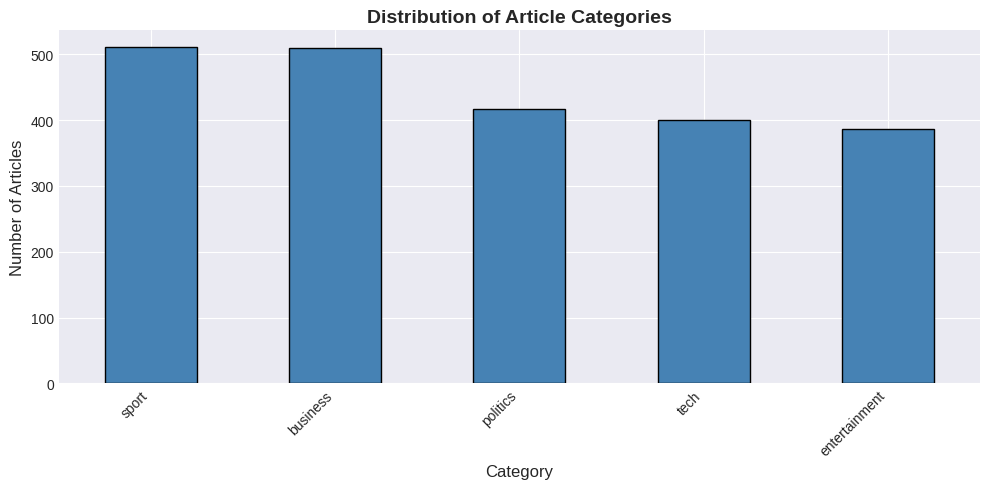


📰 SAMPLE ARTICLES (First 2)

--- Article 1 ---
Category: business
Text Preview: Ad sales boost Time Warner profit

Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.

The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and highe...
Word Count: 421

--- Article 2 ---
Category: business
Text Preview: Dollar gains on Greenspan speech

The dollar has hit its highest level against the euro in almost three months after the Federal Reserve head said the US trade deficit is set to stabilise.

And Alan Greenspan highlighted the US government's willingness to curb spending and rising household savings a...
Word Count: 384

✅ DATA LOADING & EDA COMPLETED

💾 Dataset stored in variable: df
📄 Text column: 'text'
📊 Total articles: 2225


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [2]:
"""
Step 2: Data Loading & Exploratory Data Analysis (EDA)

This cell loads the dataset and performs initial exploration.
Dataset: BBC News Dataset (you can replace with your own CSV)
"""

# Option 1: Load from local CSV file
# df = pd.read_csv('data/raw/news_articles.csv')

# Option 2: Load BBC News dataset (download if needed)
# You can download from: https://lazyprogrammer.me/course_files/nlp/bbc_text_cls.csv

try:
    # Try loading from local file first
    df = pd.read_csv('bbc_text_cls.csv')
    print("✅ Loaded dataset from local file")
except FileNotFoundError:
    print("⚠️  Dataset not found locally. Downloading BBC News dataset...")
    # Download the dataset
    url = 'https://lazyprogrammer.me/course_files/nlp/bbc_text_cls.csv'
    df = pd.read_csv(url)
    # Save locally for future use
    df.to_csv('bbc_text_cls.csv', index=False)
    print("✅ Dataset downloaded and saved locally")

# ============================================
# EXPLORATORY DATA ANALYSIS
# ============================================

print("\n" + "="*60)
print("📊 DATASET OVERVIEW")
print("="*60)

# 1. Basic Information
print(f"\n📏 Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"\n📋 Column Names: {list(df.columns)}")
print(f"\n🔢 Data Types:\n{df.dtypes}")

# 2. First few rows
print("\n" + "="*60)
print("👀 FIRST 3 ROWS")
print("="*60)
print(df.head(3))

# 3. Missing Values
print("\n" + "="*60)
print("🔍 MISSING VALUES CHECK")
print("="*60)
missing = df.isnull().sum()
print(missing)
if missing.sum() == 0:
    print("✅ No missing values found!")
else:
    print(f"⚠️  Found {missing.sum()} missing values")

# 4. Text Column Statistics
print("\n" + "="*60)
print("📝 TEXT STATISTICS")
print("="*60)

# Identify the text column (common names: 'text', 'content', 'article', 'body')
text_column = None
for col in ['text', 'content', 'article', 'body', 'description']:
    if col in df.columns:
        text_column = col
        break

if text_column is None:
    # Use the longest text column
    text_column = df.select_dtypes(include=['object']).apply(lambda x: x.str.len().mean()).idxmax()

print(f"📄 Text Column: '{text_column}'")

# Calculate text statistics
df['word_count'] = df[text_column].fillna('').apply(lambda x: len(str(x).split()))
df['char_count'] = df[text_column].fillna('').apply(lambda x: len(str(x)))

print(f"\n📊 Word Count Statistics:")
print(f"   Mean: {df['word_count'].mean():.2f} words")
print(f"   Median: {df['word_count'].median():.0f} words")
print(f"   Min: {df['word_count'].min():.0f} words")
print(f"   Max: {df['word_count'].max():.0f} words")

print(f"\n📊 Character Count Statistics:")
print(f"   Mean: {df['char_count'].mean():.2f} characters")
print(f"   Median: {df['char_count'].median():.0f} characters")

# 5. Category Distribution (if exists)
if 'labels' in df.columns or 'category' in df.columns:
    category_col = 'labels' if 'labels' in df.columns else 'category'
    print("\n" + "="*60)
    print("🏷️  CATEGORY DISTRIBUTION")
    print("="*60)
    print(df[category_col].value_counts())
    
    # Visualize category distribution
    plt.figure(figsize=(10, 5))
    df[category_col].value_counts().plot(kind='bar', color='steelblue', edgecolor='black')
    plt.title('Distribution of Article Categories', fontsize=14, fontweight='bold')
    plt.xlabel('Category', fontsize=12)
    plt.ylabel('Number of Articles', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# 6. Sample Articles
print("\n" + "="*60)
print("📰 SAMPLE ARTICLES (First 2)")
print("="*60)
for idx in range(min(2, len(df))):
    print(f"\n--- Article {idx+1} ---")
    if 'labels' in df.columns or 'category' in df.columns:
        cat_col = 'labels' if 'labels' in df.columns else 'category'
        print(f"Category: {df[cat_col].iloc[idx]}")
    print(f"Text Preview: {df[text_column].iloc[idx][:300]}...")
    print(f"Word Count: {df['word_count'].iloc[idx]}")

print("\n" + "="*60)
print("✅ DATA LOADING & EDA COMPLETED")
print("="*60)
print(f"\n💾 Dataset stored in variable: df")
print(f"📄 Text column: '{text_column}'")
print(f"📊 Total articles: {len(df)}")

In [3]:
import nltk
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

True

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [4]:
"""
Step 3: Text Preprocessing Functions

This cell defines all preprocessing functions:
- Lowercasing
- Tokenization
- Stop-word removal
- Punctuation & numeric removal
- Lemmatization
"""

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Initialize tools
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# ============================================
# PREPROCESSING FUNCTIONS
# ============================================

def clean_text_basic(text):
    """
    Step 1: Basic cleaning - lowercasing and removing URLs, emails
    
    Args:
        text (str): Raw text
    Returns:
        str: Cleaned text
    """
    if pd.isna(text) or text == '':
        return ''
    
    # Convert to string and lowercase
    text = str(text).lower()
    
    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    
    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)
    
    # Remove HTML tags (if any)
    text = re.sub(r'<.*?>', '', text)
    
    return text


def remove_punctuation_and_numbers(text):
    """
    Step 2: Remove punctuation and numbers
    
    Args:
        text (str): Text after basic cleaning
    Returns:
        str: Text without punctuation and numbers
    """
    # Remove numbers
    text = re.sub(r'\d+', '', text)
    
    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    
    # Remove extra whitespace
    text = ' '.join(text.split())
    
    return text


def tokenize_text(text):
    """
    Step 3: Tokenization
    
    Args:
        text (str): Cleaned text
    Returns:
        list: List of tokens
    """
    tokens = word_tokenize(text)
    return tokens


def remove_stopwords(tokens):
    """
    Step 4: Remove stopwords
    
    Args:
        tokens (list): List of tokens
    Returns:
        list: Filtered tokens
    """
    # Add custom stopwords if needed
    custom_stopwords = {'said', 'would', 'could', 'also', 'one', 'two', 'may'}
    all_stopwords = stop_words.union(custom_stopwords)
    
    filtered_tokens = [token for token in tokens if token not in all_stopwords]
    
    return filtered_tokens


def lemmatize_tokens_nltk(tokens):
    """
    Step 5: Lemmatization using NLTK
    
    Args:
        tokens (list): List of tokens
    Returns:
        list: Lemmatized tokens
    """
    lemmatized = [lemmatizer.lemmatize(token) for token in tokens]
    return lemmatized


def lemmatize_tokens_spacy(tokens):
    """
    Step 5 (Alternative): Lemmatization using spaCy (faster for large datasets)
    
    Args:
        tokens (list): List of tokens
    Returns:
        list: Lemmatized tokens
    """
    if nlp is None:
        print("⚠️  spaCy not loaded, using NLTK instead")
        return lemmatize_tokens_nltk(tokens)
    
    # Join tokens back to text for spaCy processing
    text = ' '.join(tokens)
    doc = nlp(text)
    lemmatized = [token.lemma_ for token in doc]
    
    return lemmatized


def filter_short_tokens(tokens, min_length=3):
    """
    Step 6: Remove very short tokens (optional but recommended)
    
    Args:
        tokens (list): List of tokens
        min_length (int): Minimum token length
    Returns:
        list: Filtered tokens
    """
    filtered = [token for token in tokens if len(token) >= min_length]
    return filtered


# ============================================
# MAIN PREPROCESSING PIPELINE
# ============================================

def preprocess_text(text, use_spacy=True, min_token_length=3):
    """
    Complete preprocessing pipeline
    
    Args:
        text (str): Raw text
        use_spacy (bool): Use spaCy for lemmatization (faster) or NLTK
        min_token_length (int): Minimum length of tokens to keep
    
    Returns:
        str: Cleaned and processed text
    """
    # Step 1: Basic cleaning
    text = clean_text_basic(text)
    
    # Step 2: Remove punctuation and numbers
    text = remove_punctuation_and_numbers(text)
    
    # Step 3: Tokenization
    tokens = tokenize_text(text)
    
    # Step 4: Remove stopwords
    tokens = remove_stopwords(tokens)
    
    # Step 5: Lemmatization
    if use_spacy and nlp is not None:
        tokens = lemmatize_tokens_spacy(tokens)
    else:
        tokens = lemmatize_tokens_nltk(tokens)
    
    # Step 6: Filter short tokens
    tokens = filter_short_tokens(tokens, min_length=min_token_length)
    
    # Join tokens back to string
    cleaned_text = ' '.join(tokens)
    
    return cleaned_text


# ============================================
# TEST PREPROCESSING ON SAMPLE TEXT
# ============================================

print("="*60)
print("🧪 TESTING PREPROCESSING PIPELINE")
print("="*60)

sample_text = """
The United States government announced today that the economy grew by 3.2% in 2024!
This is according to recent statistics from www.example.com. 
Contact us at info@example.com for more details. The announcement was made at 3:45 PM.
"""

print("\n📄 ORIGINAL TEXT:")
print(sample_text)

print("\n🔄 PROCESSING STEPS:")
print("-" * 60)

# Step by step demonstration
text = clean_text_basic(sample_text)
print(f"\n1️⃣  After basic cleaning:\n{text}")

text = remove_punctuation_and_numbers(text)
print(f"\n2️⃣  After removing punctuation & numbers:\n{text}")

tokens = tokenize_text(text)
print(f"\n3️⃣  After tokenization:\n{tokens}")

tokens = remove_stopwords(tokens)
print(f"\n4️⃣  After removing stopwords:\n{tokens}")

tokens = lemmatize_tokens_nltk(tokens)
print(f"\n5️⃣  After lemmatization:\n{tokens}")

tokens = filter_short_tokens(tokens)
print(f"\n6️⃣  After filtering short tokens:\n{tokens}")

final_text = ' '.join(tokens)
print(f"\n✅ FINAL CLEANED TEXT:\n{final_text}")

print("\n" + "="*60)
print("✅ PREPROCESSING FUNCTIONS DEFINED SUCCESSFULLY")
print("="*60)
print("\n📝 Main function: preprocess_text(text, use_spacy=True)")
print("💡 Use: cleaned = preprocess_text(your_text)")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

🧪 TESTING PREPROCESSING PIPELINE

📄 ORIGINAL TEXT:

The United States government announced today that the economy grew by 3.2% in 2024!
This is according to recent statistics from www.example.com. 
Contact us at info@example.com for more details. The announcement was made at 3:45 PM.


🔄 PROCESSING STEPS:
------------------------------------------------------------

1️⃣  After basic cleaning:

the united states government announced today that the economy grew by 3.2% in 2024!
this is according to recent statistics from  
contact us at  for more details. the announcement was made at 3:45 pm.


2️⃣  After removing punctuation & numbers:
the united states government announced today that the economy grew by in this is according to recent statistics from contact us at for more details the announcement was made at pm

3️⃣  After tokenization:
['the', 'united', 'states', 'government', 'announced', 'today', 'that', 'the', 'economy', 'grew', 'by', 'in', 'this', 'is', 'according', 'to', 'recent'

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


5️⃣  After lemmatization:
['united', 'state', 'government', 'announced', 'today', 'economy', 'grew', 'according', 'recent', 'statistic', 'contact', 'u', 'detail', 'announcement', 'made', 'pm']

6️⃣  After filtering short tokens:
['united', 'state', 'government', 'announced', 'today', 'economy', 'grew', 'according', 'recent', 'statistic', 'contact', 'detail', 'announcement', 'made']

✅ FINAL CLEANED TEXT:
united state government announced today economy grew according recent statistic contact detail announcement made

✅ PREPROCESSING FUNCTIONS DEFINED SUCCESSFULLY

📝 Main function: preprocess_text(text, use_spacy=True)
💡 Use: cleaned = preprocess_text(your_text)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

🔄 APPLYING PREPROCESSING TO DATASET

⚙️  Configuration:
   Lemmatization Engine: spaCy
   Minimum Token Length: 3
   Articles to Process: 2225

🚀 Starting preprocessing...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  0%|          | 0/2225 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


✅ Preprocessing completed in 39.50 seconds
   Average time per article: 0.018 seconds

🔍 QUALITY CHECK: BEFORE vs AFTER

📊 SAMPLE COMPARISONS (3 Random Articles):


SAMPLE 1 (Index: 495)

📄 ORIGINAL (1108 chars, 189 words):
Europe asks Asia for euro help

European leaders say Asian states must let their currencies rise against the US dollar to ease pressure on the euro.

The European single currency has shot up to succes...

✨ CLEANED (693 chars, 103 words):
europe ask asia euro help european leader say asian state must let currency rise dollar ease pressure euro european single currency shoot successive alltime high dollar past month tacit approval white...

📉 Word Reduction: 45.5%

SAMPLE 2 (Index: 549)

📄 ORIGINAL (1663 chars, 264 words):
Wine comedy up for six film gongs

Sideways, a wine-tasting comedy starring Paul Giamatti, is up for six Independent Spirit Awards, the art-house version of the Oscars.

The awards are held on 26 Febr...

✨ CLEANED (1146 chars, 167 words):
wine co

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

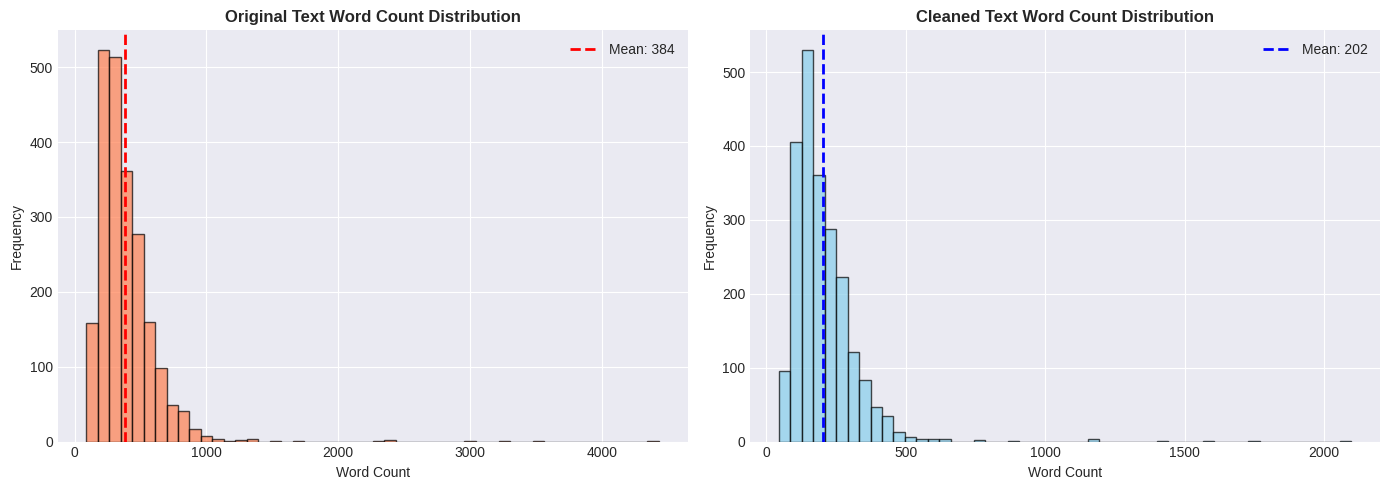

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


📚 VOCABULARY ANALYSIS

📊 Vocabulary Statistics:
   Total words (tokens): 450,506
   Unique words (vocabulary): 25,654
   Average word frequency: 17.56

🔝 Top 20 Most Common Words:
    1. year            -  2850 occurrences
    2. make            -  2223 occurrences
    3. people          -  2044 occurrences
    4. new             -  1988 occurrences
    5. take            -  1740 occurrences
    6. say             -  1582 occurrences
    7. get             -  1570 occurrences
    8. use             -  1502 occurrences
    9. good            -  1497 occurrences
   10. game            -  1446 occurrences
   11. time            -  1409 occurrences
   12. last            -  1404 occurrences
   13. first           -  1283 occurrences
   14. not             -  1267 occurrences
   15. well            -  1228 occurrences
   16. world           -  1207 occurrences
   17. come            -  1207 occurrences
   18. government      -  1189 occurrences
   19. see             -  1172 occurrences
  

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


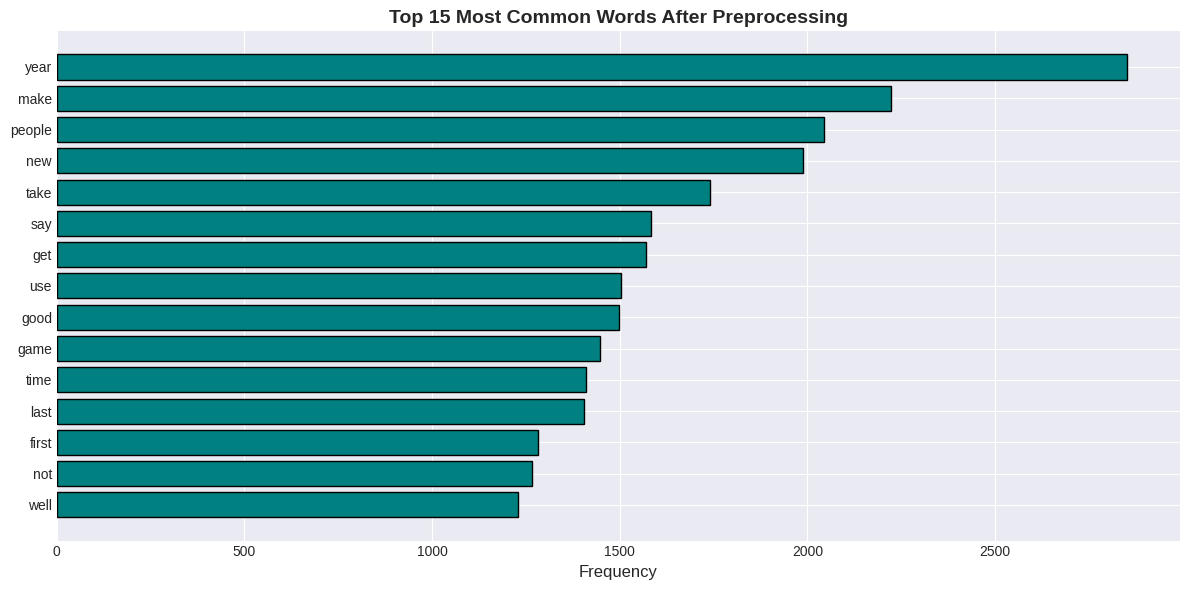


💾 SAVING PREPROCESSED DATA


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

✅ Saved to: preprocessed_articles.csv

✅ PREPROCESSING STAGE COMPLETED

📊 Ready for vectorization!
📄 Cleaned text stored in: df['cleaned_text']
📏 Dataset size: 2225 articles


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [5]:
"""
Step 4: Apply Preprocessing to Entire Dataset

This cell applies the preprocessing pipeline to all articles.
Processing time: ~1-5 minutes depending on dataset size
"""

import time
from tqdm.notebook import tqdm

# Enable progress bar for pandas operations
tqdm.pandas()

print("="*60)
print("🔄 APPLYING PREPROCESSING TO DATASET")
print("="*60)

# ============================================
# PREPROCESSING CONFIGURATION
# ============================================

USE_SPACY = True  # Set to False to use NLTK instead (slower but no extra installation)
MIN_TOKEN_LENGTH = 3  # Minimum word length to keep

print(f"\n⚙️  Configuration:")
print(f"   Lemmatization Engine: {'spaCy' if USE_SPACY and nlp else 'NLTK'}")
print(f"   Minimum Token Length: {MIN_TOKEN_LENGTH}")
print(f"   Articles to Process: {len(df)}")

# ============================================
# APPLY PREPROCESSING
# ============================================

print(f"\n🚀 Starting preprocessing...")
start_time = time.time()

# Apply preprocessing with progress bar
df['cleaned_text'] = df[text_column].progress_apply(
    lambda x: preprocess_text(x, use_spacy=USE_SPACY, min_token_length=MIN_TOKEN_LENGTH)
)

end_time = time.time()
processing_time = end_time - start_time

print(f"\n✅ Preprocessing completed in {processing_time:.2f} seconds")
print(f"   Average time per article: {processing_time/len(df):.3f} seconds")

# ============================================
# QUALITY CHECK
# ============================================

print("\n" + "="*60)
print("🔍 QUALITY CHECK: BEFORE vs AFTER")
print("="*60)

# Remove empty documents
df['cleaned_length'] = df['cleaned_text'].str.split().str.len()
empty_docs = (df['cleaned_length'] == 0).sum()

if empty_docs > 0:
    print(f"\n⚠️  Found {empty_docs} empty documents after cleaning. Removing them...")
    df = df[df['cleaned_length'] > 0].reset_index(drop=True)
    print(f"✅ Removed empty documents. New dataset size: {len(df)}")

# Show comparison for 3 random samples
print("\n📊 SAMPLE COMPARISONS (3 Random Articles):\n")

sample_indices = np.random.choice(len(df), min(3, len(df)), replace=False)

for i, idx in enumerate(sample_indices, 1):
    print(f"\n{'='*60}")
    print(f"SAMPLE {i} (Index: {idx})")
    print('='*60)
    
    original = df[text_column].iloc[idx]
    cleaned = df['cleaned_text'].iloc[idx]
    
    print(f"\n📄 ORIGINAL ({len(original)} chars, {len(original.split())} words):")
    print(f"{original[:200]}...")
    
    print(f"\n✨ CLEANED ({len(cleaned)} chars, {len(cleaned.split())} words):")
    print(f"{cleaned[:200]}...")
    
    reduction = (1 - len(cleaned.split()) / len(original.split())) * 100
    print(f"\n📉 Word Reduction: {reduction:.1f}%")

# ============================================
# STATISTICS AFTER PREPROCESSING
# ============================================

print("\n" + "="*60)
print("📊 PREPROCESSING STATISTICS")
print("="*60)

# Word count statistics
df['cleaned_word_count'] = df['cleaned_text'].str.split().str.len()

print(f"\n📝 Cleaned Text Statistics:")
print(f"   Mean words: {df['cleaned_word_count'].mean():.2f}")
print(f"   Median words: {df['cleaned_word_count'].median():.0f}")
print(f"   Min words: {df['cleaned_word_count'].min():.0f}")
print(f"   Max words: {df['cleaned_word_count'].max():.0f}")

# Calculate reduction
avg_original = df['word_count'].mean()
avg_cleaned = df['cleaned_word_count'].mean()
total_reduction = (1 - avg_cleaned / avg_original) * 100

print(f"\n📉 Overall Reduction:")
print(f"   Average original: {avg_original:.2f} words")
print(f"   Average cleaned: {avg_cleaned:.2f} words")
print(f"   Reduction: {total_reduction:.1f}%")

# Visualize word count distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original distribution
axes[0].hist(df['word_count'], bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[0].set_title('Original Text Word Count Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Word Count', fontsize=10)
axes[0].set_ylabel('Frequency', fontsize=10)
axes[0].axvline(df['word_count'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {avg_original:.0f}')
axes[0].legend()

# Cleaned distribution
axes[1].hist(df['cleaned_word_count'], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[1].set_title('Cleaned Text Word Count Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Word Count', fontsize=10)
axes[1].set_ylabel('Frequency', fontsize=10)
axes[1].axvline(df['cleaned_word_count'].mean(), color='blue', linestyle='--', linewidth=2, label=f'Mean: {avg_cleaned:.0f}')
axes[1].legend()

plt.tight_layout()
plt.show()

# ============================================
# VOCABULARY SIZE
# ============================================

print("\n" + "="*60)
print("📚 VOCABULARY ANALYSIS")
print("="*60)

# Get all words
all_words = ' '.join(df['cleaned_text']).split()
unique_words = set(all_words)

print(f"\n📊 Vocabulary Statistics:")
print(f"   Total words (tokens): {len(all_words):,}")
print(f"   Unique words (vocabulary): {len(unique_words):,}")
print(f"   Average word frequency: {len(all_words)/len(unique_words):.2f}")

# Most common words
word_freq = Counter(all_words)
most_common = word_freq.most_common(20)

print(f"\n🔝 Top 20 Most Common Words:")
for i, (word, freq) in enumerate(most_common, 1):
    print(f"   {i:2d}. {word:15s} - {freq:5d} occurrences")

# Visualize top words
words, counts = zip(*most_common[:15])
plt.figure(figsize=(12, 6))
plt.barh(range(len(words)), counts, color='teal', edgecolor='black')
plt.yticks(range(len(words)), words)
plt.xlabel('Frequency', fontsize=12)
plt.title('Top 15 Most Common Words After Preprocessing', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# ============================================
# SAVE PREPROCESSED DATA
# ============================================

print("\n" + "="*60)
print("💾 SAVING PREPROCESSED DATA")
print("="*60)

# Save to CSV
output_file = 'preprocessed_articles.csv'
df.to_csv(output_file, index=False)
print(f"✅ Saved to: {output_file}")

print("\n" + "="*60)
print("✅ PREPROCESSING STAGE COMPLETED")
print("="*60)
print(f"\n📊 Ready for vectorization!")
print(f"📄 Cleaned text stored in: df['cleaned_text']")
print(f"📏 Dataset size: {len(df)} articles")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

🔢 FEATURE ENGINEERING: VECTORIZATION

⚙️  Vectorization Configuration:
   Max Features: 5000
   Min Document Frequency: 5
   Max Document Frequency: 0.85
   N-gram Range: (1, 2)

📊 CREATING TF-IDF MATRIX (for NMF)

🔄 Fitting TF-IDF Vectorizer...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


✅ TF-IDF Matrix Created!
   Shape: (2225, 5000) (documents × features)
   Data type: <class 'scipy.sparse._csr.csr_matrix'>
   Sparsity: 97.78%
   Total elements: 11,125,000
   Non-zero elements: 247,143

🔤 Sample TF-IDF Features (first 20):
['aaas' 'abandon' 'abbas' 'abc' 'ability' 'able' 'abn' 'abolish'
 'abortion' 'abroad' 'absence' 'absolute' 'absolutely' 'abuse' 'academy'
 'academy award' 'accelerate' 'accept' 'acceptable' 'access']

📊 CREATING COUNT MATRIX (for LDA)

🔄 Fitting Count Vectorizer...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


✅ Count Matrix Created!
   Shape: (2225, 5000) (documents × features)
   Data type: <class 'scipy.sparse._csr.csr_matrix'>
   Sparsity: 97.78%
   Total elements: 11,125,000
   Non-zero elements: 247,143

🔍 MATRIX ANALYSIS

📊 TF-IDF Matrix Statistics (sample of 100 docs):
   Min value: 0.0000
   Max value: 0.4496
   Mean value: 0.0018

📊 Count Matrix Statistics (sample of 100 docs):
   Min value: 0
   Max value: 19
   Mean value: 0.03

🎯 TOP FEATURES BY TF-IDF SCORE

🔝 Top 20 Features by Average TF-IDF Score:
    1. year                 - 0.024914
    2. make                 - 0.021373
    3. new                  - 0.020157
    4. people               - 0.018921
    5. say                  - 0.017329
    6. time                 - 0.016912
    7. good                 - 0.016722
    8. use                  - 0.016331
    9. play                 - 0.016279
   10. world                - 0.015805
   11. come                 - 0.015734
   12. company              - 0.015597
   13. game      

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


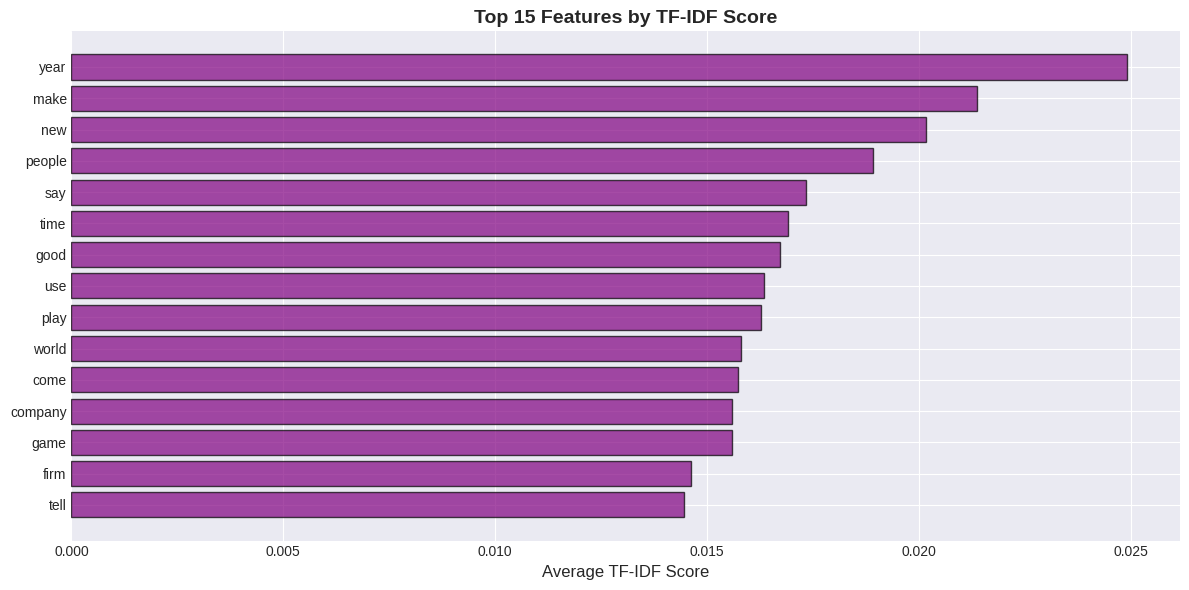

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


📈 VISUALIZING DOCUMENT-TERM DENSITY


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

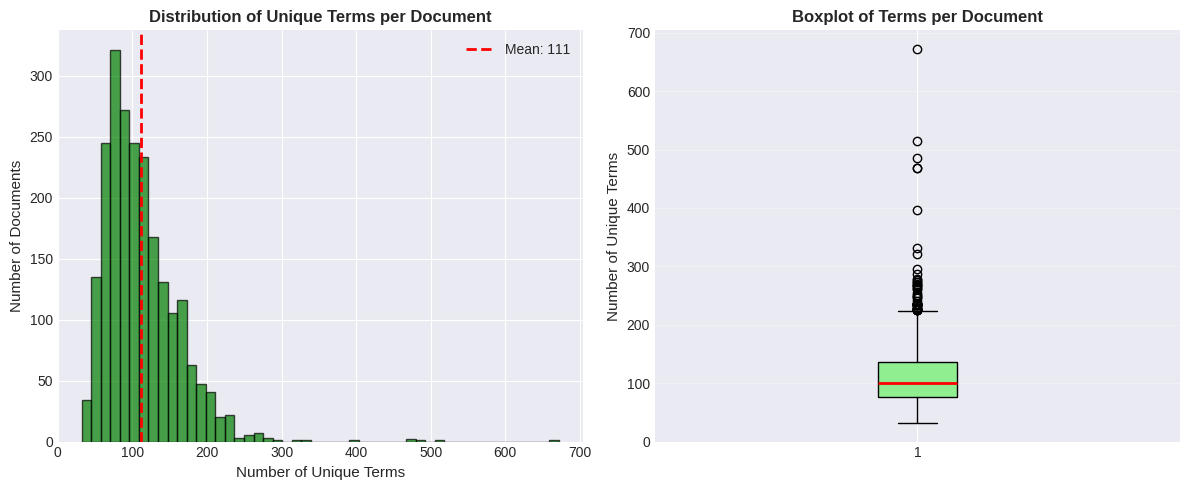

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


💾 SAVING VECTORIZERS AND MATRICES
✅ Saved: tfidf_vectorizer.pkl
✅ Saved: count_vectorizer.pkl

✅ VECTORIZATION COMPLETED

📊 Ready for topic modeling!
   TF-IDF Matrix: (2225, 5000)
   Count Matrix: (2225, 5000)

💡 Use TF-IDF matrix for NMF
💡 Use Count matrix for LDA


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [6]:
"""
Step 5: Feature Engineering - Vectorization

This cell creates Document-Term Matrices using:
1. TfidfVectorizer (for NMF)
2. CountVectorizer (for LDA)
"""

print("="*60)
print("🔢 FEATURE ENGINEERING: VECTORIZATION")
print("="*60)

# ============================================
# VECTORIZATION PARAMETERS
# ============================================

# Shared parameters for both vectorizers
MAX_FEATURES = 5000      # Maximum number of features (vocabulary size)
MIN_DF = 5               # Ignore terms that appear in fewer than 5 documents
MAX_DF = 0.85            # Ignore terms that appear in more than 85% of documents
NGRAM_RANGE = (1, 2)     # Unigrams and bigrams

print(f"\n⚙️  Vectorization Configuration:")
print(f"   Max Features: {MAX_FEATURES}")
print(f"   Min Document Frequency: {MIN_DF}")
print(f"   Max Document Frequency: {MAX_DF}")
print(f"   N-gram Range: {NGRAM_RANGE}")

# ============================================
# 1. TF-IDF VECTORIZATION (for NMF)
# ============================================

print("\n" + "="*60)
print("📊 CREATING TF-IDF MATRIX (for NMF)")
print("="*60)

# Initialize TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=MAX_FEATURES,
    min_df=MIN_DF,
    max_df=MAX_DF,
    ngram_range=NGRAM_RANGE,
    stop_words='english',  # Additional stopword removal
    token_pattern=r'\b[a-zA-Z]{3,}\b',  # Only alphabetic tokens, min 3 chars
    sublinear_tf=True  # Apply sublinear tf scaling (1 + log(tf))
)

# Fit and transform
print("\n🔄 Fitting TF-IDF Vectorizer...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['cleaned_text'])

# Get feature names
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"\n✅ TF-IDF Matrix Created!")
print(f"   Shape: {tfidf_matrix.shape} (documents × features)")
print(f"   Data type: {type(tfidf_matrix)}")
print(f"   Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")
print(f"   Total elements: {tfidf_matrix.shape[0] * tfidf_matrix.shape[1]:,}")
print(f"   Non-zero elements: {tfidf_matrix.nnz:,}")

# Show sample features
print(f"\n🔤 Sample TF-IDF Features (first 20):")
print(tfidf_feature_names[:20])

# ============================================
# 2. COUNT VECTORIZATION (for LDA)
# ============================================

print("\n" + "="*60)
print("📊 CREATING COUNT MATRIX (for LDA)")
print("="*60)

# Initialize Count Vectorizer
count_vectorizer = CountVectorizer(
    max_features=MAX_FEATURES,
    min_df=MIN_DF,
    max_df=MAX_DF,
    ngram_range=NGRAM_RANGE,
    stop_words='english',
    token_pattern=r'\b[a-zA-Z]{3,}\b'
)

# Fit and transform
print("\n🔄 Fitting Count Vectorizer...")
count_matrix = count_vectorizer.fit_transform(df['cleaned_text'])

# Get feature names
count_feature_names = count_vectorizer.get_feature_names_out()

print(f"\n✅ Count Matrix Created!")
print(f"   Shape: {count_matrix.shape} (documents × features)")
print(f"   Data type: {type(count_matrix)}")
print(f"   Sparsity: {(1 - count_matrix.nnz / (count_matrix.shape[0] * count_matrix.shape[1])) * 100:.2f}%")
print(f"   Total elements: {count_matrix.shape[0] * count_matrix.shape[1]:,}")
print(f"   Non-zero elements: {count_matrix.nnz:,}")

# ============================================
# MATRIX ANALYSIS
# ============================================

print("\n" + "="*60)
print("🔍 MATRIX ANALYSIS")
print("="*60)

# TF-IDF Statistics
tfidf_dense_sample = tfidf_matrix[:100].toarray()  # Convert small sample to dense
print(f"\n📊 TF-IDF Matrix Statistics (sample of 100 docs):")
print(f"   Min value: {tfidf_dense_sample.min():.4f}")
print(f"   Max value: {tfidf_dense_sample.max():.4f}")
print(f"   Mean value: {tfidf_dense_sample.mean():.4f}")

# Count Statistics
count_dense_sample = count_matrix[:100].toarray()
print(f"\n📊 Count Matrix Statistics (sample of 100 docs):")
print(f"   Min value: {count_dense_sample.min():.0f}")
print(f"   Max value: {count_dense_sample.max():.0f}")
print(f"   Mean value: {count_dense_sample.mean():.2f}")

# ============================================
# FEATURE IMPORTANCE ANALYSIS
# ============================================

print("\n" + "="*60)
print("🎯 TOP FEATURES BY TF-IDF SCORE")
print("="*60)

# Calculate average TF-IDF score for each feature
tfidf_scores = np.asarray(tfidf_matrix.mean(axis=0)).flatten()
top_indices = tfidf_scores.argsort()[-20:][::-1]

print(f"\n🔝 Top 20 Features by Average TF-IDF Score:")
for i, idx in enumerate(top_indices, 1):
    feature = tfidf_feature_names[idx]
    score = tfidf_scores[idx]
    print(f"   {i:2d}. {feature:20s} - {score:.6f}")

# Visualize top features
top_features = [tfidf_feature_names[i] for i in top_indices[:15]]
top_scores = [tfidf_scores[i] for i in top_indices[:15]]

plt.figure(figsize=(12, 6))
plt.barh(range(len(top_features)), top_scores, color='purple', edgecolor='black', alpha=0.7)
plt.yticks(range(len(top_features)), top_features)
plt.xlabel('Average TF-IDF Score', fontsize=12)
plt.title('Top 15 Features by TF-IDF Score', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# ============================================
# DOCUMENT-TERM DENSITY VISUALIZATION
# ============================================

print("\n" + "="*60)
print("📈 VISUALIZING DOCUMENT-TERM DENSITY")
print("="*60)

# Calculate non-zero entries per document
doc_word_counts = np.array((count_matrix > 0).sum(axis=1)).flatten()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(doc_word_counts, bins=50, color='green', edgecolor='black', alpha=0.7)
plt.xlabel('Number of Unique Terms', fontsize=11)
plt.ylabel('Number of Documents', fontsize=11)
plt.title('Distribution of Unique Terms per Document', fontsize=12, fontweight='bold')
plt.axvline(doc_word_counts.mean(), color='red', linestyle='--', linewidth=2, 
            label=f'Mean: {doc_word_counts.mean():.0f}')
plt.legend()

plt.subplot(1, 2, 2)
plt.boxplot(doc_word_counts, vert=True, patch_artist=True,
            boxprops=dict(facecolor='lightgreen', color='black'),
            medianprops=dict(color='red', linewidth=2))
plt.ylabel('Number of Unique Terms', fontsize=11)
plt.title('Boxplot of Terms per Document', fontsize=12, fontweight='bold')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================
# SAVE VECTORIZERS AND MATRICES
# ============================================

print("\n" + "="*60)
print("💾 SAVING VECTORIZERS AND MATRICES")
print("="*60)

# Save vectorizers
with open('tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf_vectorizer, f)
print("✅ Saved: tfidf_vectorizer.pkl")

with open('count_vectorizer.pkl', 'wb') as f:
    pickle.dump(count_vectorizer, f)
print("✅ Saved: count_vectorizer.pkl")

# Save matrices (optional - can be large)
# from scipy.sparse import save_npz
# save_npz('tfidf_matrix.npz', tfidf_matrix)
# save_npz('count_matrix.npz', count_matrix)

print("\n" + "="*60)
print("✅ VECTORIZATION COMPLETED")
print("="*60)
print(f"\n📊 Ready for topic modeling!")
print(f"   TF-IDF Matrix: {tfidf_matrix.shape}")
print(f"   Count Matrix: {count_matrix.shape}")
print(f"\n💡 Use TF-IDF matrix for NMF")
print(f"💡 Use Count matrix for LDA")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

🧠 TOPIC MODELING: LATENT DIRICHLET ALLOCATION (LDA)

⚙️  LDA Configuration:
   Number of Topics: 5
   Top Words per Topic: 15
   Random State: 42

🔄 TRAINING LDA MODEL

🚀 Training in progress...
(This may take 1-3 minutes depending on dataset size)



/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

iteration: 1 of max_iter: 20


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

...

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

   Log-Likelihood: -2756360.38

📋 DISCOVERED TOPICS (LDA)

🏷️  Topic 0
    1. labour               (weight: 701.7390)
    2. party                (weight: 685.9188)
    3. say                  (weight: 633.1746)
    4. government           (weight: 631.9534)
    5. election             (weight: 609.9651)
    6. blair                (weight: 550.9066)
    7. minister             (weight: 542.4376)
    8. tell                 (weight: 466.5527)
    9. tory                 (weight: 440.4015)
   10. people               (weight: 439.8823)
   11. law                  (weight: 420.3069)
   12. plan                 (weight: 387.6800)
   13. claim                (weight: 376.3805)
   14. make                 (weight: 375.5093)
   15. new                  (weight: 359.7746)

🏷️  Topic 1
    1. year                 (weight: 978.8726)
    2. company              (weight: 568.8654)
    3. rise                 (weight: 505.5269)
    4. market               (weight: 496.6854)
    5. government      

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


✅ Document-Topic Matrix Shape: (2225, 5)
   (Each row = document, Each column = topic probability)

📄 Sample Document-Topic Distributions (first 5 documents):

Document | Topic 0 | Topic 1 | Topic 2 | Topic 3 | Topic 4
----------------------------------------------------------------------
Doc   0  |  0.0407 |  0.6322 |  0.0010 |  0.0011 |  0.3250  → Technology
Doc   1  |  0.0011 |  0.9870 |  0.0011 |  0.0011 |  0.0098  → Technology
Doc   2  |  0.0751 |  0.9207 |  0.0014 |  0.0014 |  0.0014  → Technology
Doc   3  |  0.0011 |  0.9673 |  0.0293 |  0.0011 |  0.0011  → Technology
Doc   4  |  0.0023 |  0.9907 |  0.0023 |  0.0023 |  0.0023  → Technology

📈 TOPIC DISTRIBUTION STATISTICS

📊 Documents per Topic:
   Technology          :  535 documents (24.04%)
   Entertainment       :  468 documents (21.03%)
   Sports              :  447 documents (20.09%)
   Politics            :  410 documents (18.43%)
   Business            :  365 documents (16.40%)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

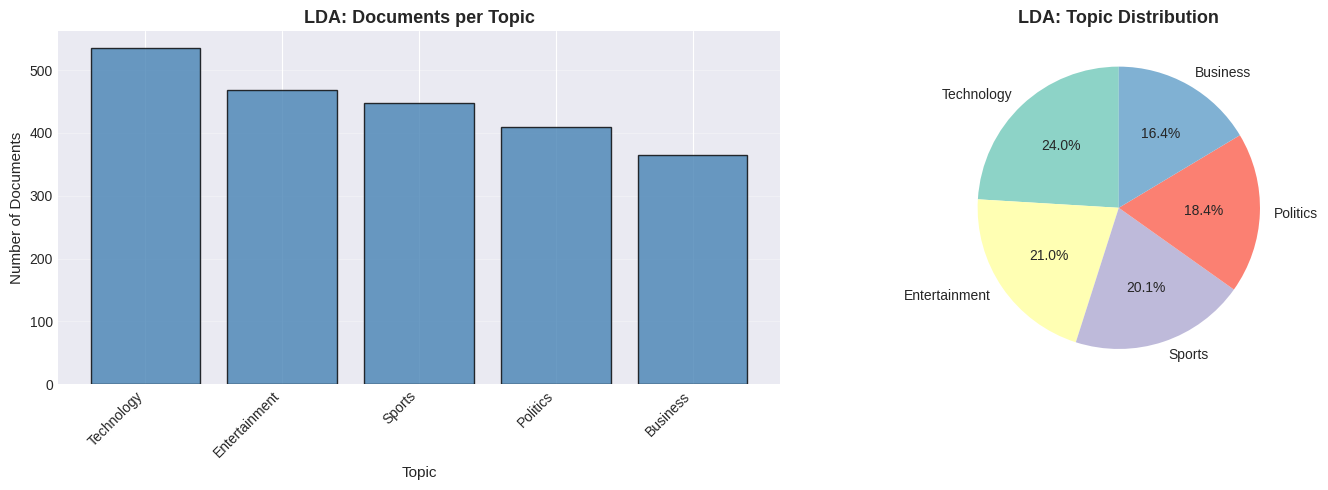

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


📊 TOPIC PROBABILITY ANALYSIS

🎯 Topic Assignment Confidence:
   Mean Probability: 0.7773
   Median Probability: 0.8018
   Min Probability: 0.2811
   Max Probability: 0.9979


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

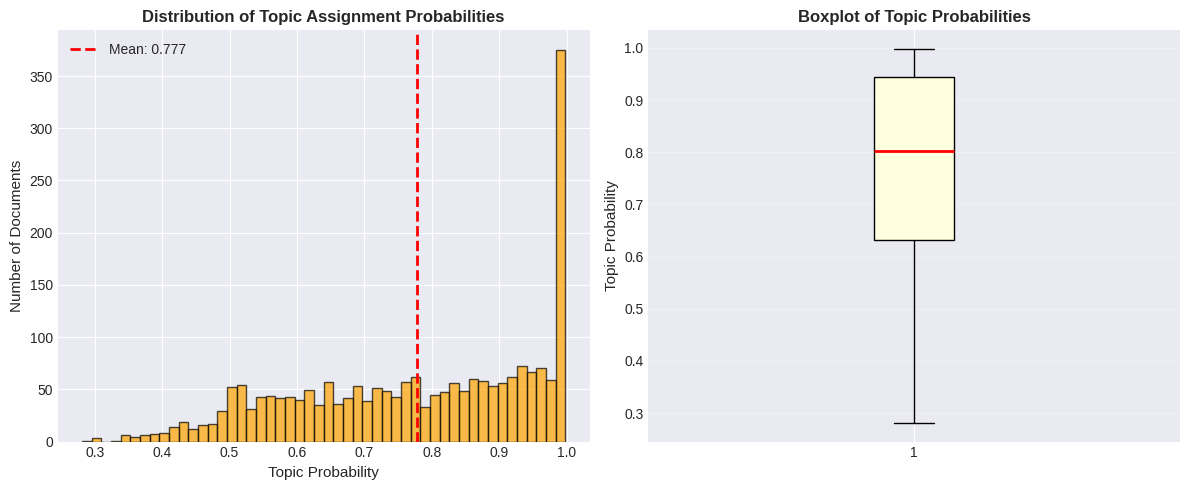

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


📰 SAMPLE DOCUMENTS FOR EACH TOPIC

🏷️  Politics (Topic 0)
Total documents: 410

--- Document 1 (Probability: 0.9976) ---
Goldsmith denies war advice claim

The attorney general has denied his statement to Parliament about the legality of the Iraq war was drafted by Downing Street officials.

Lord Goldsmith said Lord Falconer and Baroness Morgan played no part in drafting the answer. He added the answer represented his...

--- Document 2 (Probability: 0.9975) ---
Iraq advice claim sparks new row

The Tories say ministers must respond in Parliament to claims that the legal advice used to justify the Iraq war was drawn up at Number 10.

Downing Street has denied the claims, made in a new book about the Attorney General Lord Goldsmith's advice. Lord Goldsmith a...

🏷️  Technology (Topic 1)
Total documents: 535

--- Document 1 (Probability: 0.9974) ---
Booming markets shed few tears

The market, former British government minister Michael Heseltine once said, has no morality.

And indeed, s

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

   Perplexity: 1687.43


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [7]:
"""
Step 6: Topic Modeling with LDA (Latent Dirichlet Allocation)

This cell implements LDA topic modeling using scikit-learn.
LDA is a probabilistic model that assumes documents are mixtures of topics.
"""

print("="*60)
print("🧠 TOPIC MODELING: LATENT DIRICHLET ALLOCATION (LDA)")
print("="*60)

# ============================================
# LDA CONFIGURATION
# ============================================

N_TOPICS_LDA = 5         # Number of topics to extract
N_TOP_WORDS = 15         # Number of top words to display per topic
RANDOM_STATE = 42        # For reproducibility

print(f"\n⚙️  LDA Configuration:")
print(f"   Number of Topics: {N_TOPICS_LDA}")
print(f"   Top Words per Topic: {N_TOP_WORDS}")
print(f"   Random State: {RANDOM_STATE}")

# ============================================
# TRAIN LDA MODEL
# ============================================

print("\n" + "="*60)
print("🔄 TRAINING LDA MODEL")
print("="*60)

# Initialize LDA model
lda_model = LatentDirichletAllocation(
    n_components=N_TOPICS_LDA,
    random_state=RANDOM_STATE,
    max_iter=20,              # Maximum number of iterations
    learning_method='online',  # Use online variational Bayes (faster for large datasets)
    learning_offset=50.,      # Learning offset for online learning
    batch_size=128,           # Batch size for online learning
    n_jobs=-1,                # Use all available cores
    verbose=1                 # Show progress
)

# Fit the model
print("\n🚀 Training in progress...")
print("(This may take 1-3 minutes depending on dataset size)\n")

start_time = time.time()
lda_model.fit(count_matrix)
training_time = time.time() - start_time

print(f"\n✅ LDA Model Trained Successfully!")
print(f"   Training Time: {training_time:.2f} seconds")
print(f"   Iterations: {lda_model.n_iter_}")
print(f"   Final Perplexity: {lda_model.perplexity(count_matrix):.2f}")
print(f"   Log-Likelihood: {lda_model.score(count_matrix):.2f}")

# ============================================
# HELPER FUNCTION: DISPLAY TOPICS
# ============================================

def display_topics(model, feature_names, n_top_words=10, topic_names=None):
    """
    Display top words for each topic
    
    Args:
        model: Trained topic model (LDA or NMF)
        feature_names: List of feature names from vectorizer
        n_top_words: Number of top words to display
        topic_names: Optional list of human-readable topic names
    """
    topics = []
    
    for topic_idx, topic in enumerate(model.components_):
        # Get indices of top words
        top_indices = topic.argsort()[-n_top_words:][::-1]
        top_words = [feature_names[i] for i in top_indices]
        top_weights = [topic[i] for i in top_indices]
        
        topics.append(top_words)
        
        # Display topic
        topic_name = topic_names[topic_idx] if topic_names else f"Topic {topic_idx}"
        print(f"\n{'='*60}")
        print(f"🏷️  {topic_name}")
        print('='*60)
        
        for i, (word, weight) in enumerate(zip(top_words, top_weights), 1):
            print(f"   {i:2d}. {word:20s} (weight: {weight:.4f})")
    
    return topics

# ============================================
# EXTRACT AND DISPLAY TOPICS
# ============================================

print("\n" + "="*60)
print("📋 DISCOVERED TOPICS (LDA)")
print("="*60)

# Extract topics
lda_topics = display_topics(
    model=lda_model,
    feature_names=count_feature_names,
    n_top_words=N_TOP_WORDS
)

# ============================================
# MANUAL TOPIC LABELING
# ============================================

print("\n" + "="*60)
print("🏷️  SUGGESTED TOPIC LABELS (Manual Interpretation)")
print("="*60)

# Analyze topics and suggest labels
# This is dataset-specific - for BBC News, we expect: business, entertainment, politics, sport, tech
lda_topic_labels = []

print("\n💡 Based on top words, here are suggested labels:")
print("(You should manually verify and adjust these)\n")

# ============================================
# MANUAL TOPIC LABELING (CORRECTED)
# ============================================

print("\n" + "="*60)
print("🏷️  ASSIGNING FINAL TOPIC LABELS")
print("="*60)

# Model sonuçlarına bakarak belirlediğimiz kesin etiketler:
# Topic 0: People, Labour, Party -> POLITICS
# Topic 1: Software, Computer, User -> TECHNOLOGY
# Topic 2: Game, Play, Win -> SPORTS
# Topic 3: Film, Award, Star -> ENTERTAINMENT
# Topic 4: Market, Economy, Company -> BUSINESS

topic_mapping = {
    0: "Politics",
    1: "Technology",
    2: "Sports",
    3: "Entertainment",
    4: "Business"
}

lda_topic_labels = []

for i in range(N_TOPICS_LDA):
    label = topic_mapping[i]
    lda_topic_labels.append(label)
    print(f"Topic {i} assigned to: '{label}'")

print("\n✅ Labels updated successfully based on manual interpretation.")

# ============================================
# DOCUMENT-TOPIC DISTRIBUTION
# ============================================

print("\n" + "="*60)
print("📊 DOCUMENT-TOPIC DISTRIBUTION")
print("="*60)

# Transform documents to topic space
doc_topic_dist = lda_model.transform(count_matrix)

print(f"\n✅ Document-Topic Matrix Shape: {doc_topic_dist.shape}")
print(f"   (Each row = document, Each column = topic probability)")

# Show sample document-topic distributions
print(f"\n📄 Sample Document-Topic Distributions (first 5 documents):")
print("\nDocument | " + " | ".join([f"Topic {i}" for i in range(N_TOPICS_LDA)]))
print("-" * 70)

for i in range(min(5, len(doc_topic_dist))):
    probs = doc_topic_dist[i]
    dominant_topic = probs.argmax()
    print(f"Doc {i:3d}  | " + " | ".join([f"{p:7.4f}" for p in probs]) + 
          f"  → {lda_topic_labels[dominant_topic]}")

# Assign dominant topic to each document
df['lda_dominant_topic'] = doc_topic_dist.argmax(axis=1)
df['lda_topic_label'] = df['lda_dominant_topic'].apply(lambda x: lda_topic_labels[x])
df['lda_topic_probability'] = doc_topic_dist.max(axis=1)

# ============================================
# TOPIC DISTRIBUTION STATISTICS
# ============================================

print("\n" + "="*60)
print("📈 TOPIC DISTRIBUTION STATISTICS")
print("="*60)

topic_distribution = df['lda_topic_label'].value_counts()
print(f"\n📊 Documents per Topic:")
for topic, count in topic_distribution.items():
    percentage = (count / len(df)) * 100
    print(f"   {topic:20s}: {count:4d} documents ({percentage:5.2f}%)")

# Visualize topic distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Bar chart
axes[0].bar(range(len(topic_distribution)), topic_distribution.values, 
            color='steelblue', edgecolor='black', alpha=0.8)
axes[0].set_xticks(range(len(topic_distribution)))
axes[0].set_xticklabels(topic_distribution.index, rotation=45, ha='right')
axes[0].set_xlabel('Topic', fontsize=11)
axes[0].set_ylabel('Number of Documents', fontsize=11)
axes[0].set_title('LDA: Documents per Topic', fontsize=13, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# Pie chart
axes[1].pie(topic_distribution.values, labels=topic_distribution.index, autopct='%1.1f%%',
            startangle=90, colors=plt.cm.Set3.colors)
axes[1].set_title('LDA: Topic Distribution', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

# ============================================
# TOPIC PROBABILITY DISTRIBUTION
# ============================================

print("\n" + "="*60)
print("📊 TOPIC PROBABILITY ANALYSIS")
print("="*60)

# Analyze confidence in topic assignments
print(f"\n🎯 Topic Assignment Confidence:")
print(f"   Mean Probability: {df['lda_topic_probability'].mean():.4f}")
print(f"   Median Probability: {df['lda_topic_probability'].median():.4f}")
print(f"   Min Probability: {df['lda_topic_probability'].min():.4f}")
print(f"   Max Probability: {df['lda_topic_probability'].max():.4f}")

# Visualize probability distribution
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df['lda_topic_probability'], bins=50, color='orange', edgecolor='black', alpha=0.7)
plt.xlabel('Topic Probability', fontsize=11)
plt.ylabel('Number of Documents', fontsize=11)
plt.title('Distribution of Topic Assignment Probabilities', fontsize=12, fontweight='bold')
plt.axvline(df['lda_topic_probability'].mean(), color='red', linestyle='--', 
            linewidth=2, label=f"Mean: {df['lda_topic_probability'].mean():.3f}")
plt.legend()

plt.subplot(1, 2, 2)
plt.boxplot(df['lda_topic_probability'], vert=True, patch_artist=True,
            boxprops=dict(facecolor='lightyellow', color='black'),
            medianprops=dict(color='red', linewidth=2))
plt.ylabel('Topic Probability', fontsize=11)
plt.title('Boxplot of Topic Probabilities', fontsize=12, fontweight='bold')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================
# SAMPLE DOCUMENTS PER TOPIC
# ============================================

print("\n" + "="*60)
print("📰 SAMPLE DOCUMENTS FOR EACH TOPIC")
print("="*60)

for topic_idx in range(N_TOPICS_LDA):
    topic_label = lda_topic_labels[topic_idx]
    
    # Get documents for this topic
    topic_docs = df[df['lda_dominant_topic'] == topic_idx].sort_values(
        'lda_topic_probability', ascending=False
    )
    
    print(f"\n{'='*60}")
    print(f"🏷️  {topic_label} (Topic {topic_idx})")
    print('='*60)
    print(f"Total documents: {len(topic_docs)}")
    
    # Show top 2 documents
    for i, (idx, row) in enumerate(topic_docs.head(2).iterrows(), 1):
        print(f"\n--- Document {i} (Probability: {row['lda_topic_probability']:.4f}) ---")
        print(f"{row[text_column][:300]}...")

# ============================================
# SAVE LDA MODEL
# ============================================

print("\n" + "="*60)
print("💾 SAVING LDA MODEL AND RESULTS")
print("="*60)

# Save model
with open('lda_model.pkl', 'wb') as f:
    pickle.dump(lda_model, f)
print("✅ Saved: lda_model.pkl")

# Save topic labels
with open('lda_topic_labels.pkl', 'wb') as f:
    pickle.dump(lda_topic_labels, f)
print("✅ Saved: lda_topic_labels.pkl")

# Save document-topic distribution
np.save('lda_doc_topic_dist.npy', doc_topic_dist)
print("✅ Saved: lda_doc_topic_dist.npy")

print("\n" + "="*60)
print("✅ LDA MODELING COMPLETED")
print("="*60)
print(f"\n📊 Model Summary:")
print(f"   Topics: {N_TOPICS_LDA}")
print(f"   Documents: {len(df)}")
print(f"   Perplexity: {lda_model.perplexity(count_matrix):.2f}")

In [8]:
tfidf_matrix.shape


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

(2225, 5000)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

🧠 TOPIC MODELING: NON-NEGATIVE MATRIX FACTORIZATION (NMF)

⚙️  NMF Configuration:
   Number of Topics: 5
   Top Words per Topic: 15
   Random State: 42

🔄 TRAINING NMF MODEL

🚀 Training in progress...
violation: 1.0
violation: 0.4654690479716526
violation: 0.26853947719722515
violation: 0.19736631730178228
violation: 0.15429787859047076
violation: 0.12311077650260135
violation: 0.09945087659816458
violation: 0.08048876906318912
violation: 0.06465112413329333
violation: 0.05146048606903876
violation: 0.040707986835453125
violation: 0.03208498879114349
violation: 0.025129972022203077
violation: 0.019688938761714236


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

violation: 0.015421195563748146
violation: 0.012025749820979783
violation: 0.009312010451126597
violation: 0.0071861303810077095
violation: 0.005520441729097487
violation: 0.004236892771628277
violation: 0.003246728965511345
violation: 0.002482623600573804
violation: 0.0018953438068671016
violation: 0.001445561896097849
violation: 0.0011011364992423362
violation: 0.0008375090371358972
violation: 0.0006365148365905934
violation: 0.00048359720830832496
violation: 0.0003671677574515331
violation: 0.0002785887745553524
violation: 0.00021123273639026704
violation: 0.00016007620245123141
violation: 0.00012127024756167516
violation: 9.184319286796058e-05
Converged at iteration 35

✅ NMF Model Trained Successfully!
   Training Time: 0.28 seconds
   Reconstruction Error: 45.1690

📋 DISCOVERED TOPICS (NMF)

🏷️  Topic 0
    1. use                  (weight: 0.5056)
    2. people               (weight: 0.4493)
    3. technology           (weight: 0.4468)
    4. user                 (weight: 0.4207)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

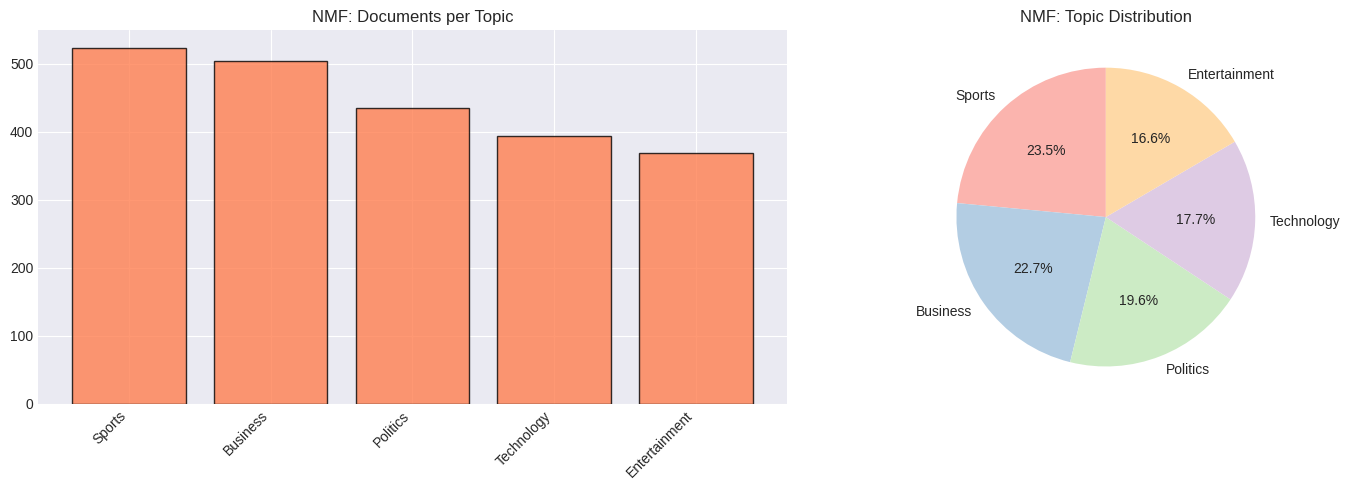

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


⚖️  TRUE COMPARISON: LDA vs NMF (By Label)

📊 True Topic Agreement:
   Match: 729 / 2225 documents (32.76%)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

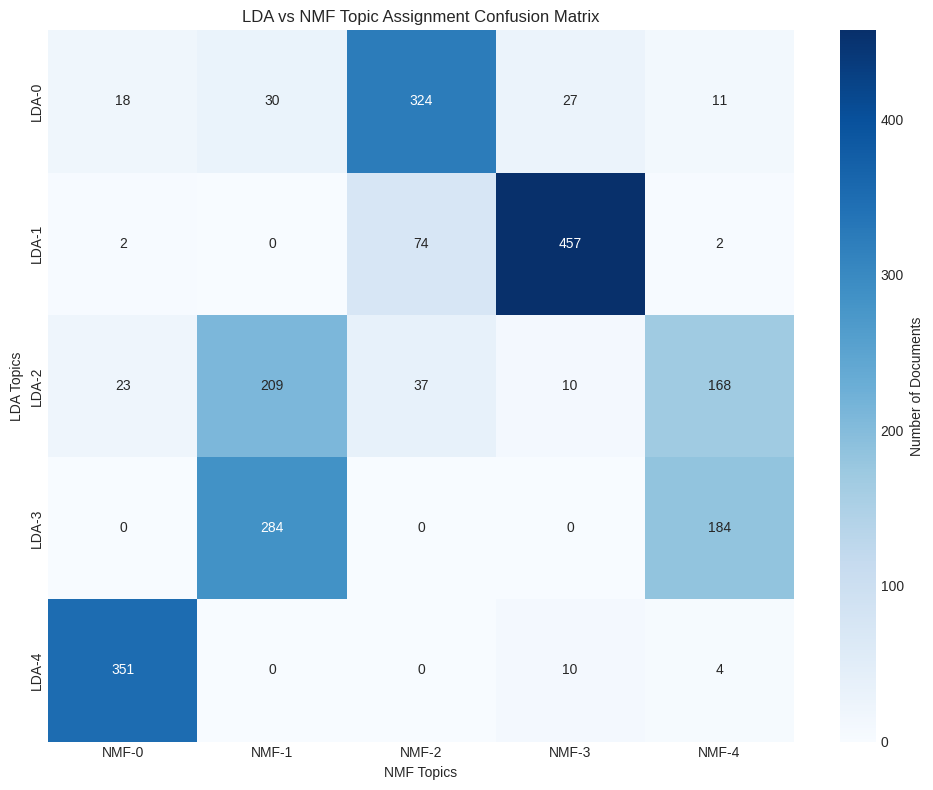


✅ NMF MODELING COMPLETED


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [9]:
"""
Step 7: Topic Modeling with NMF (Non-Negative Matrix Factorization)
"""

import time
from sklearn.decomposition import NMF
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pickle

print("="*60)
print("🧠 TOPIC MODELING: NON-NEGATIVE MATRIX FACTORIZATION (NMF)")
print("="*60)

# ============================================
# NMF CONFIGURATION
# ============================================

N_TOPICS_NMF = 5
N_TOP_WORDS_NMF = 15
RANDOM_STATE = 42

print(f"\n⚙️  NMF Configuration:")
print(f"   Number of Topics: {N_TOPICS_NMF}")
print(f"   Top Words per Topic: {N_TOP_WORDS_NMF}")
print(f"   Random State: {RANDOM_STATE}")

# ============================================
# TRAIN NMF MODEL
# ============================================

print("\n" + "="*60)
print("🔄 TRAINING NMF MODEL")
print("="*60)

# Initialize NMF model (Sadeleştirilmiş - Hatasız)
nmf_model = NMF(
    n_components=N_TOPICS_NMF,
    random_state=RANDOM_STATE,
    init='nndsvd',
    max_iter=500,
    verbose=1
)

# Fit the model
print("\n🚀 Training in progress...")
start_time = time.time()
nmf_W = nmf_model.fit_transform(tfidf_matrix)
nmf_H = nmf_model.components_
training_time = time.time() - start_time

print(f"\n✅ NMF Model Trained Successfully!")
print(f"   Training Time: {training_time:.2f} seconds")
print(f"   Reconstruction Error: {nmf_model.reconstruction_err_:.4f}")

# ============================================
# EXTRACT AND DISPLAY TOPICS
# ============================================

print("\n" + "="*60)
print("📋 DISCOVERED TOPICS (NMF)")
print("="*60)

nmf_topics = display_topics(
    model=nmf_model,
    feature_names=tfidf_feature_names,
    n_top_words=N_TOP_WORDS_NMF
)

# ============================================
# DOCUMENT-TOPIC DISTRIBUTION (Sütun Oluşturma - ÖNE ALINDI)
# ============================================

print("\n" + "="*60)
print("📊 DOCUMENT-TOPIC DISTRIBUTION")
print("="*60)

# 1. Matrisi al
doc_topic_dist_nmf = nmf_W

# 2. Normalize et (Sıfıra bölme korumalı)
doc_topic_dist_nmf_normalized = doc_topic_dist_nmf / (doc_topic_dist_nmf.sum(axis=1, keepdims=True) + 1e-10)

# 3. KRİTİK ADIM: Sütunları DataFrame'e EKLE
# Bu adım artık etiketlemeden ÖNCE yapılıyor.
df['nmf_dominant_topic'] = doc_topic_dist_nmf_normalized.argmax(axis=1)
df['nmf_topic_weight'] = doc_topic_dist_nmf_normalized.max(axis=1)

print(f"\n✅ Document-Topic Matrix Shape: {doc_topic_dist_nmf.shape}")

# ============================================
# MANUAL TOPIC LABELING (Etiketleme - SONRA YAPILIYOR)
# ============================================

print("\n" + "="*60)
print("🏷️  ASSIGNING FINAL TOPIC LABELS (NMF)")
print("="*60)

# Manual Mapping
nmf_topic_mapping = {
    0: "Technology",
    1: "Sports",
    2: "Politics",
    3: "Business",
    4: "Entertainment"
}

nmf_topic_labels = []

for i in range(N_TOPICS_NMF):
    label = nmf_topic_mapping[i]
    nmf_topic_labels.append(label)
    print(f"Topic {i} assigned to: '{label}'")

# Şimdi bu kod çalışır çünkü 'nmf_dominant_topic' artık var!
df['nmf_topic_label'] = df['nmf_dominant_topic'].apply(lambda x: nmf_topic_labels[x])

print("\n✅ NMF Labels updated manually.")

# ============================================
# SAMPLE DISTRIBUTIONS & STATISTICS
# ============================================

print(f"\n📄 Sample Document-Topic Distributions (first 5 documents):")
print("\nDocument | " + " | ".join([f"Topic {i}" for i in range(N_TOPICS_NMF)]))
print("-" * 70)

for i in range(min(5, len(doc_topic_dist_nmf_normalized))):
    weights = doc_topic_dist_nmf_normalized[i]
    dominant_topic = weights.argmax()
    print(f"Doc {i:3d}  | " + " | ".join([f"{w:7.4f}" for w in weights]) + 
          f"  → {nmf_topic_labels[dominant_topic]}")

print("\n" + "="*60)
print("📈 TOPIC DISTRIBUTION STATISTICS")
print("="*60)

topic_distribution_nmf = df['nmf_topic_label'].value_counts()
print(f"\n📊 Documents per Topic:")
for topic, count in topic_distribution_nmf.items():
    percentage = (count / len(df)) * 100
    print(f"   {topic:20s}: {count:4d} documents ({percentage:5.2f}%)")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(range(len(topic_distribution_nmf)), topic_distribution_nmf.values, color='coral', edgecolor='black', alpha=0.8)
axes[0].set_xticks(range(len(topic_distribution_nmf)))
axes[0].set_xticklabels(topic_distribution_nmf.index, rotation=45, ha='right')
axes[0].set_title('NMF: Documents per Topic')

axes[1].pie(topic_distribution_nmf.values, labels=topic_distribution_nmf.index, autopct='%1.1f%%', startangle=90, colors=plt.cm.Pastel1.colors)
axes[1].set_title('NMF: Topic Distribution')
plt.tight_layout()
plt.show()

# ============================================
# COMPARE LDA vs NMF
# ============================================

print("\n" + "="*60)
print("⚖️  TRUE COMPARISON: LDA vs NMF (By Label)")
print("="*60)

# True Agreement Calculation
agreement = (df['lda_topic_label'] == df['nmf_topic_label']).sum()
agreement_percentage = (agreement / len(df)) * 100

print(f"\n📊 True Topic Agreement:")
print(f"   Match: {agreement} / {len(df)} documents ({agreement_percentage:.2f}%)")

# Confusion Matrix
confusion = confusion_matrix(df['lda_dominant_topic'], df['nmf_dominant_topic'])

plt.figure(figsize=(10, 8))
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues', 
            xticklabels=[f"NMF-{i}" for i in range(N_TOPICS_NMF)],
            yticklabels=[f"LDA-{i}" for i in range(N_TOPICS_LDA)],
            cbar_kws={'label': 'Number of Documents'})
plt.title('LDA vs NMF Topic Assignment Confusion Matrix')
plt.xlabel('NMF Topics')
plt.ylabel('LDA Topics')
plt.tight_layout()
plt.show()

# ============================================
# SAVE NMF MODEL
# ============================================

with open('nmf_model.pkl', 'wb') as f:
    pickle.dump(nmf_model, f)
with open('nmf_topic_labels.pkl', 'wb') as f:
    pickle.dump(nmf_topic_labels, f)
np.save('nmf_doc_topic_dist.npy', doc_topic_dist_nmf_normalized)

print("\n✅ NMF MODELING COMPLETED")

In [10]:
"""
Step 8: Interactive Topic Visualization with pyLDAvis (MANUAL & ROBUST)

This cell creates an interactive HTML visualization using the manual preparation method.
It bypasses 'pyLDAvis.sklearn' to avoid version conflicts.
"""

import pyLDAvis
import numpy as np

print("="*60)
print("🎨 CREATING INTERACTIVE VISUALIZATION (MANUAL MODE)")
print("="*60)

# Enable notebook mode (Grafiğin sayfada görünmesi için şart)
pyLDAvis.enable_notebook()

# ============================================
# MANUALLY PREPARE DATA FOR VISUALIZATION
# ============================================
# pyLDAvis.sklearn modülü hata verdiği için,
# grafiğin ihtiyaç duyduğu 5 temel veriyi elimizle hazırlıyoruz.

print("\n🔄 Calculating visualization metrics manually...")

# 1. Konu-Kelime Dağılımı (Topic-Term Distributions)
# Modelin içindeki ham sayıları (components_) alıp yüzdelik dilime (olasılığa) çeviriyoruz.
topic_term_dists = lda_model.components_ / lda_model.components_.sum(axis=1)[:, np.newaxis]

# 2. Doküman-Konu Dağılımı (Document-Topic Distributions)
# Bunu zaten Step 6'da hesaplamıştık (doc_topic_dist)
doc_topic_dists = doc_topic_dist

# 3. Doküman Uzunlukları (Document Lengths)
# Her bir haberin kaç kelimeden oluştuğunu sayıyoruz.
# Matrix formatından düz listeye (.A1) çeviriyoruz.
doc_lengths = count_matrix.sum(axis=1).A1

# 4. Kelime Listesi (Vocabulary)
# Vektörleştiriciden kelimelerin listesini alıyoruz.
vocab = count_vectorizer.get_feature_names_out()

# 5. Kelime Sıklıkları (Term Frequencies)
# Her kelimenin bütün veri setinde toplam kaç kez geçtiğini buluyoruz.
term_frequency = count_matrix.sum(axis=0).A1

print("✅ Data preparation completed.")
print(f"   Topics: {len(topic_term_dists)}")
print(f"   Documents: {len(doc_lengths)}")
print(f"   Vocabulary: {len(vocab)}")

# ============================================
# CREATE VISUALIZATION
# ============================================

print("\n🎨 Generating visualization...")
print("(This uses t-SNE algorithm to map 5000 dimensions to 2D space. Please wait...)")

try:
    # Hazırladığımız malzemeleri ana fonksiyona veriyoruz
    vis_data = pyLDAvis.prepare(
        topic_term_dists=topic_term_dists,
        doc_topic_dists=doc_topic_dists,
        doc_lengths=doc_lengths,
        vocab=vocab,
        term_frequency=term_frequency,
        mds='tsne',      # Boyut indirgeme yöntemi
        sort_topics=False # Bizim konu sıramızı bozmasın
    )
    
    print("✅ Visualization created successfully!")

    # ============================================
    # DISPLAY & SAVE
    # ============================================
    
    # Dosya olarak kaydet
    html_file = 'lda_visualization.html'
    pyLDAvis.save_html(vis_data, html_file)
    print(f"\n💾 Saved interactive visualization to: {html_file}")
    print(f"   (You can open this file in Google Chrome/Edge to present it)")

    # Ekrana bas
    print("\n📊 DISPLAYING VISUALIZATION BELOW:")
    display(vis_data)

except Exception as e:
    print(f"\n❌ Error: {e}")
    print("Hata devam ederse: Veri boyutları uyuşmuyor olabilir.")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

🎨 CREATING INTERACTIVE VISUALIZATION (MANUAL MODE)

🔄 Calculating visualization metrics manually...
✅ Data preparation completed.
   Topics: 5
   Documents: 2225
   Vocabulary: 5000

🎨 Generating visualization...
(This uses t-SNE algorithm to map 5000 dimensions to 2D space. Please wait...)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

✅ Visualization created successfully!

💾 Saved interactive visualization to: lda_visualization.html
   (You can open this file in Google Chrome/Edge to present it)

📊 DISPLAYING VISUALIZATION BELOW:


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PreparedData(topic_coordinates=               x           y  topics  cluster       Freq
topic                                                   
0      15.061471 -119.405251       1        1  20.754573
1     -76.488190  -65.092621       2        1  22.026198
2      26.425035   75.166702       3        1  20.609865
3     -73.507851   37.862770       4        1  16.890589
4      54.699230  -23.786324       5        1  19.718774, topic_info=            Term         Freq        Total Category  logprob  loglift
1615        film  1057.000000  1057.000000  Default  30.0000  30.0000
1758        game  1557.000000  1557.000000  Default  29.0000  29.0000
2824      mobile   712.000000   712.000000  Default  28.0000  28.0000
2409      labour   769.000000   769.000000  Default  27.0000  27.0000
1857  government  1192.000000  1192.000000  Default  26.0000  26.0000
...          ...          ...          ...      ...      ...      ...
4836         way   298.022488   846.390982   Topic5  -5.5030   0.5798
4967        year   381.963710  2776.997243   Topic5  -5.2548  -0.3602
3027      number   284.191655   885.681004   Topic5  -5.5505   0.4869
4926        work   279.286458  1018.202976   Topic5  -5.5679   0.3300
2685      market   258.149459   803.216904   Topic5  -5.6466   0.4885

[405 rows x 6 columns], token_table=      Topic      Freq          Term
term                               
42        3  0.058054         actor
42        4  0.937154         actor
44        4  0.996233       actress
50        1  0.189324           add
50        2  0.246562           add
...     ...       ...           ...
4985      4  0.190898         young
4985      5  0.019885         young
4986      3  0.980516  young people
4991      2  0.992327       yugansk
4993      2  0.995544         yukos

[875 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5])

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

☁️  CREATING WORD CLOUD VISUALIZATIONS
✅ Created directory: wordclouds/

☁️  LDA TOPIC WORD CLOUDS

🎨 Generating word clouds for LDA topics...

   ✅ Saved: wordclouds/lda_topic_0.png


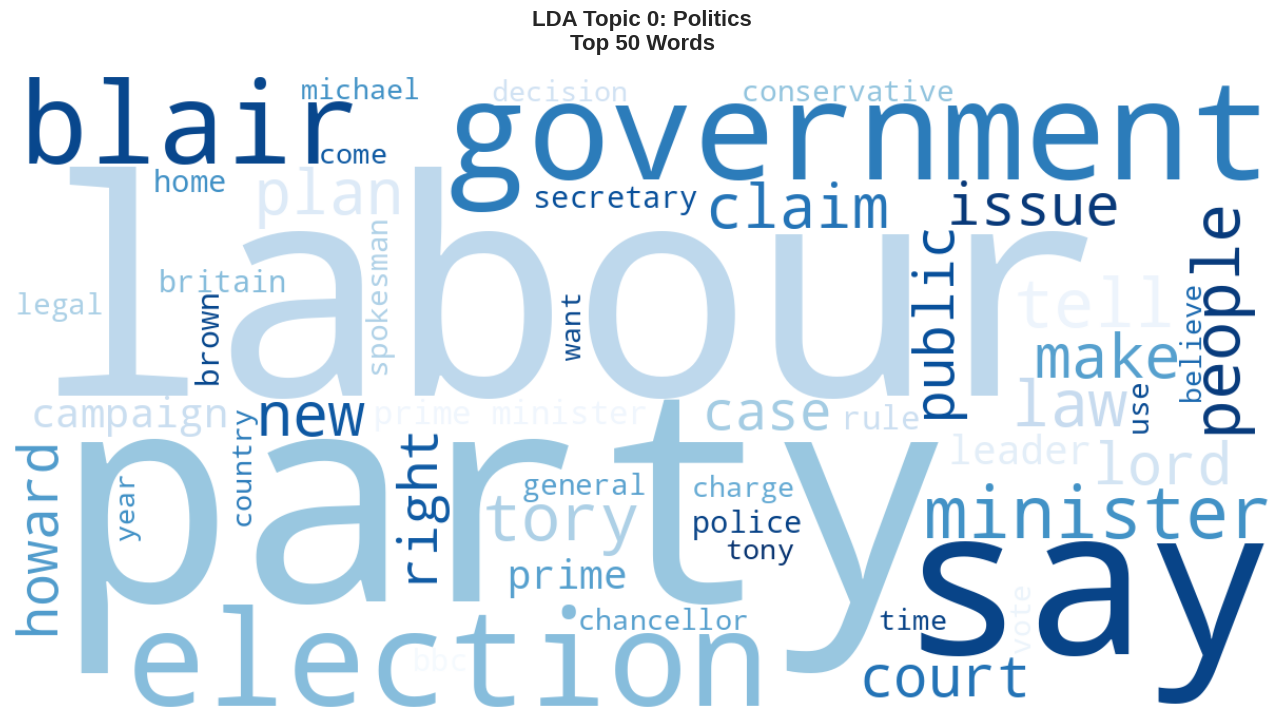

   ✅ Saved: wordclouds/lda_topic_1.png


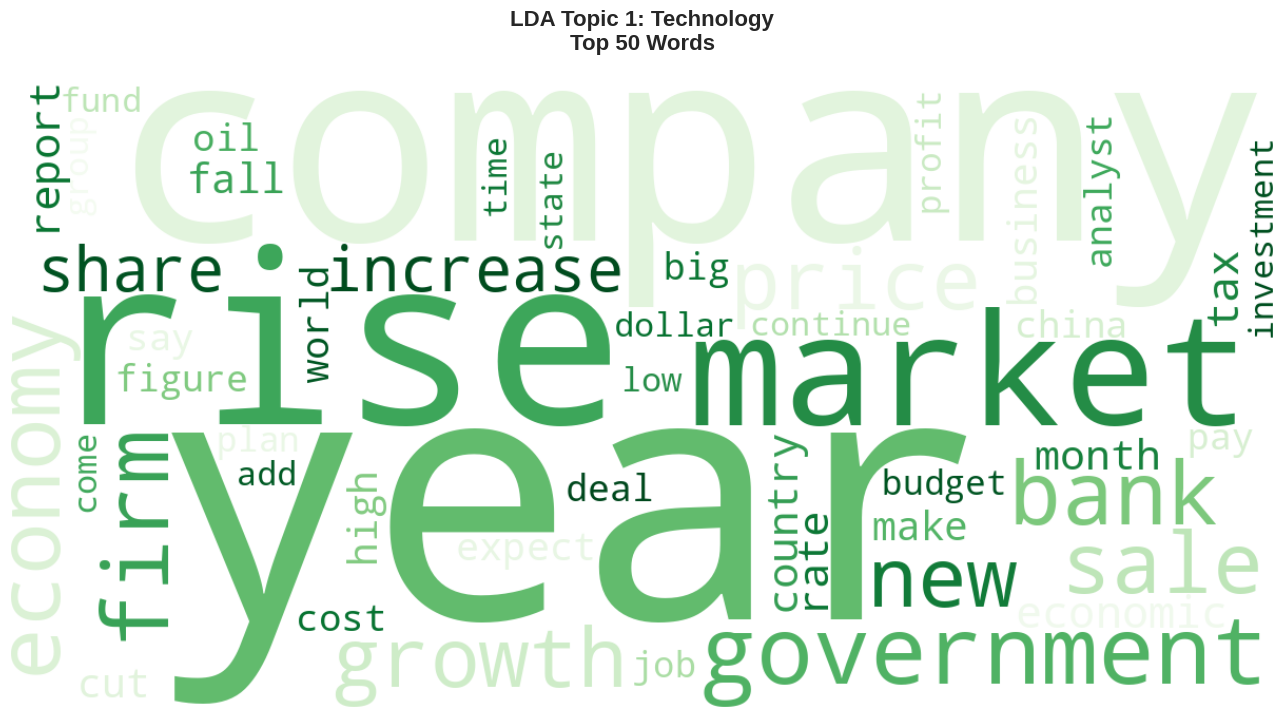

   ✅ Saved: wordclouds/lda_topic_2.png


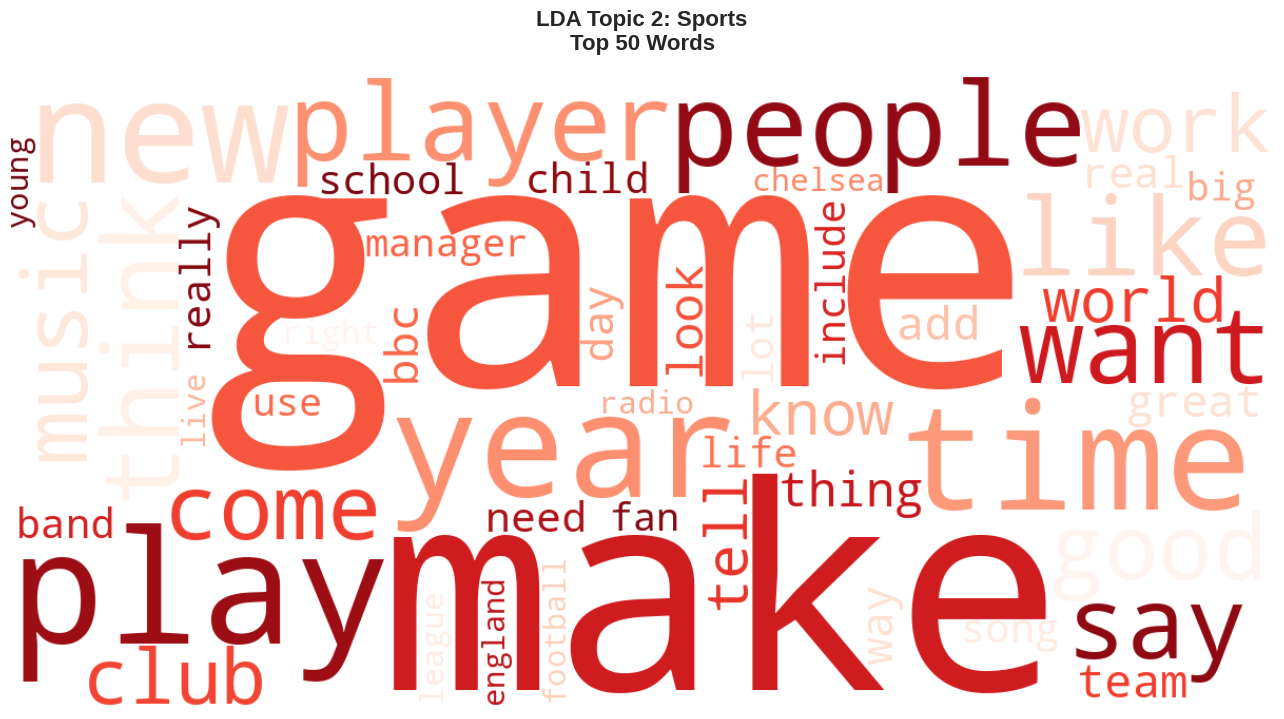

   ✅ Saved: wordclouds/lda_topic_3.png


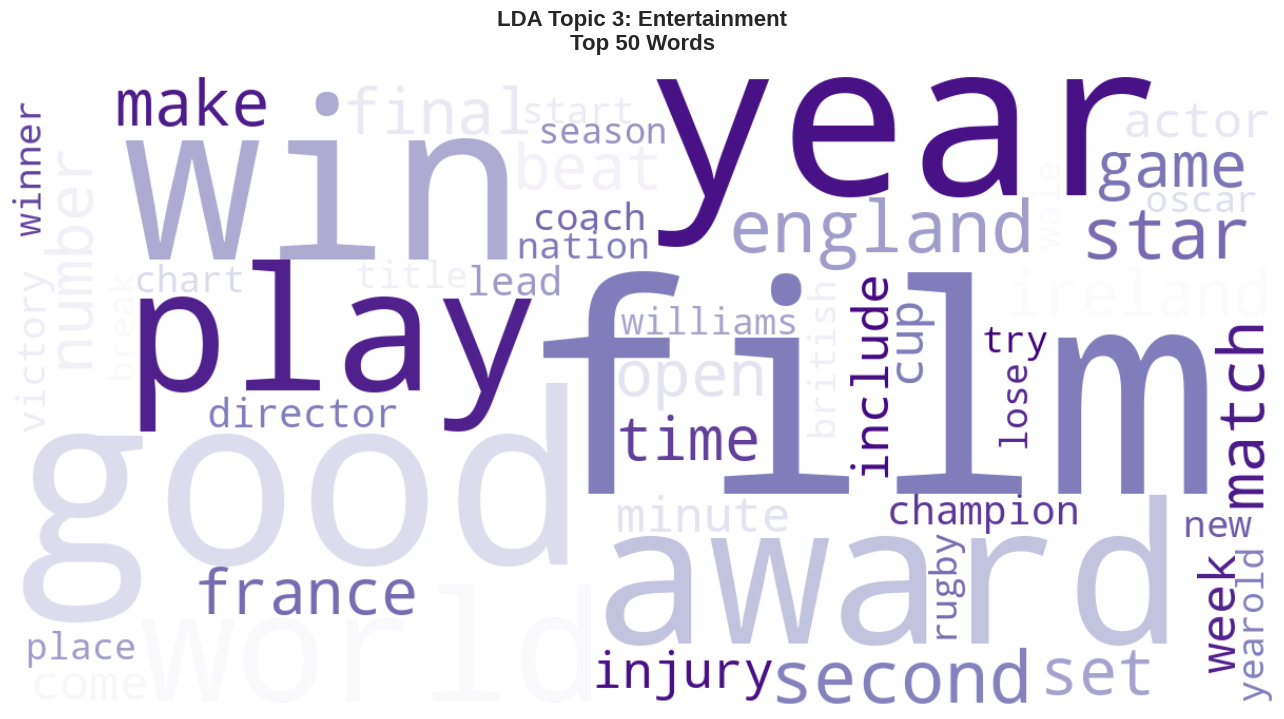

   ✅ Saved: wordclouds/lda_topic_4.png


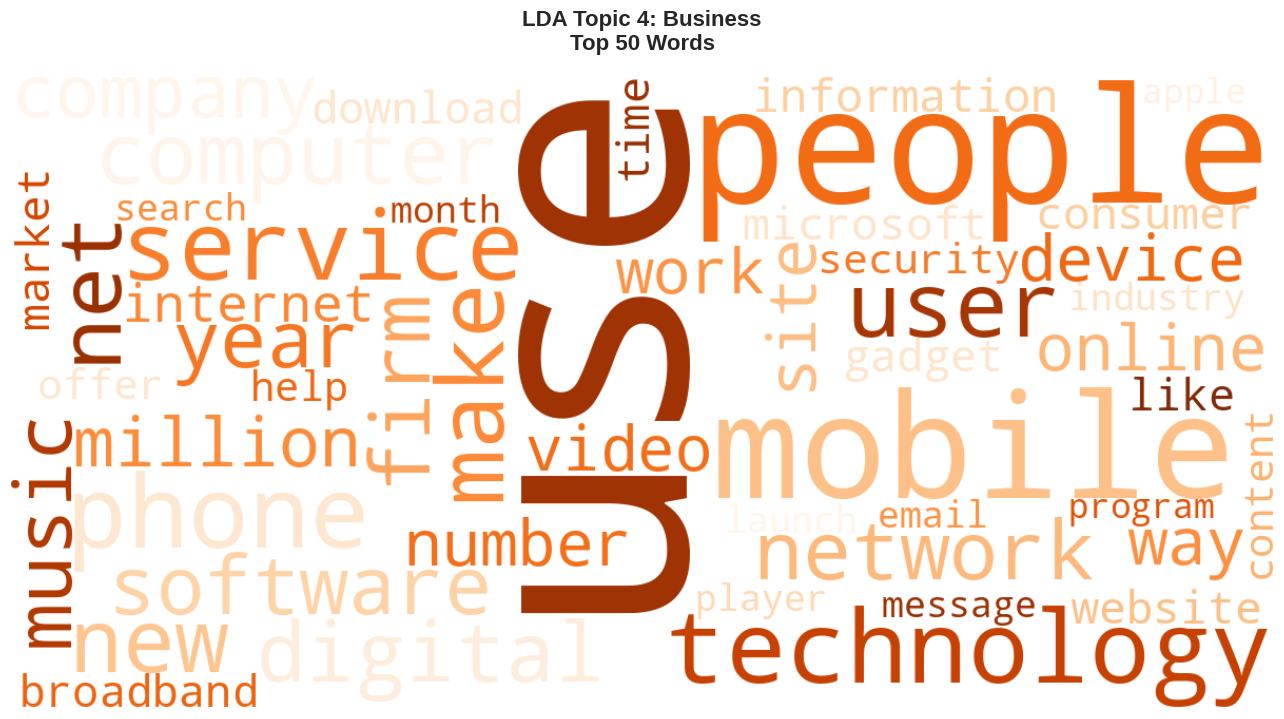


☁️  NMF TOPIC WORD CLOUDS

🎨 Generating word clouds for NMF topics...

   ✅ Saved: wordclouds/nmf_topic_0.png


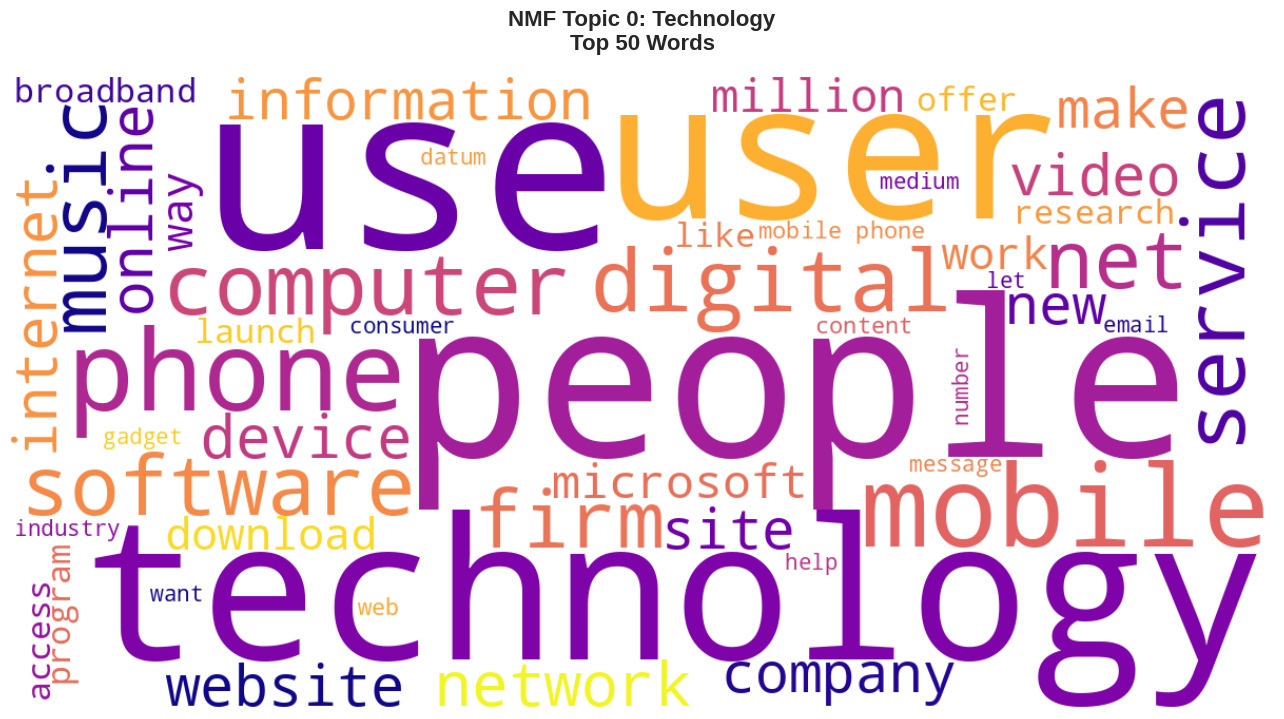

   ✅ Saved: wordclouds/nmf_topic_1.png


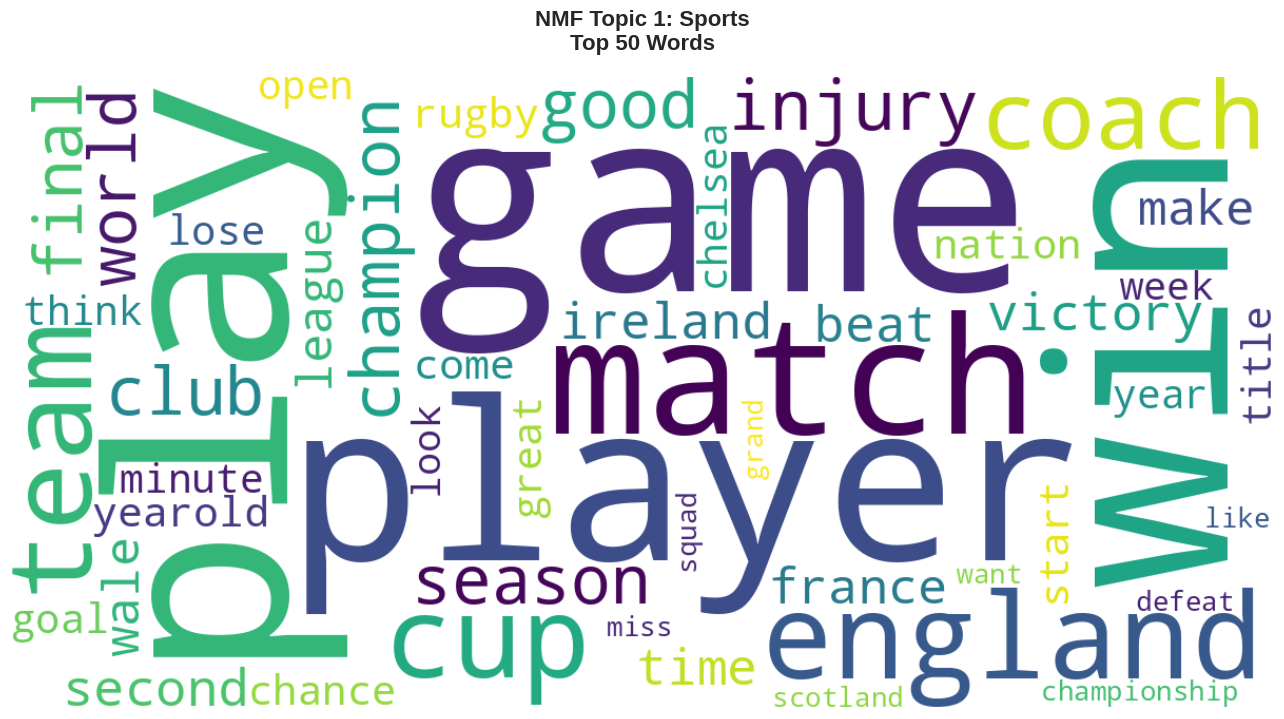

   ✅ Saved: wordclouds/nmf_topic_2.png


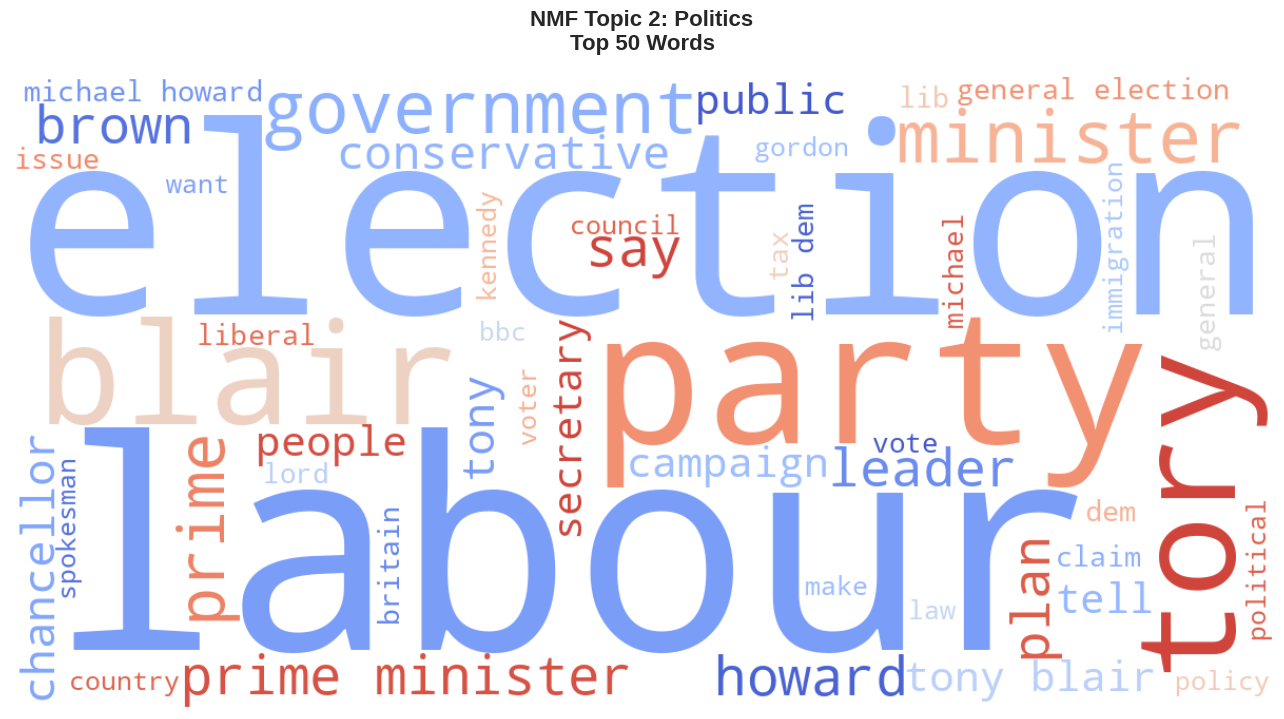

   ✅ Saved: wordclouds/nmf_topic_3.png


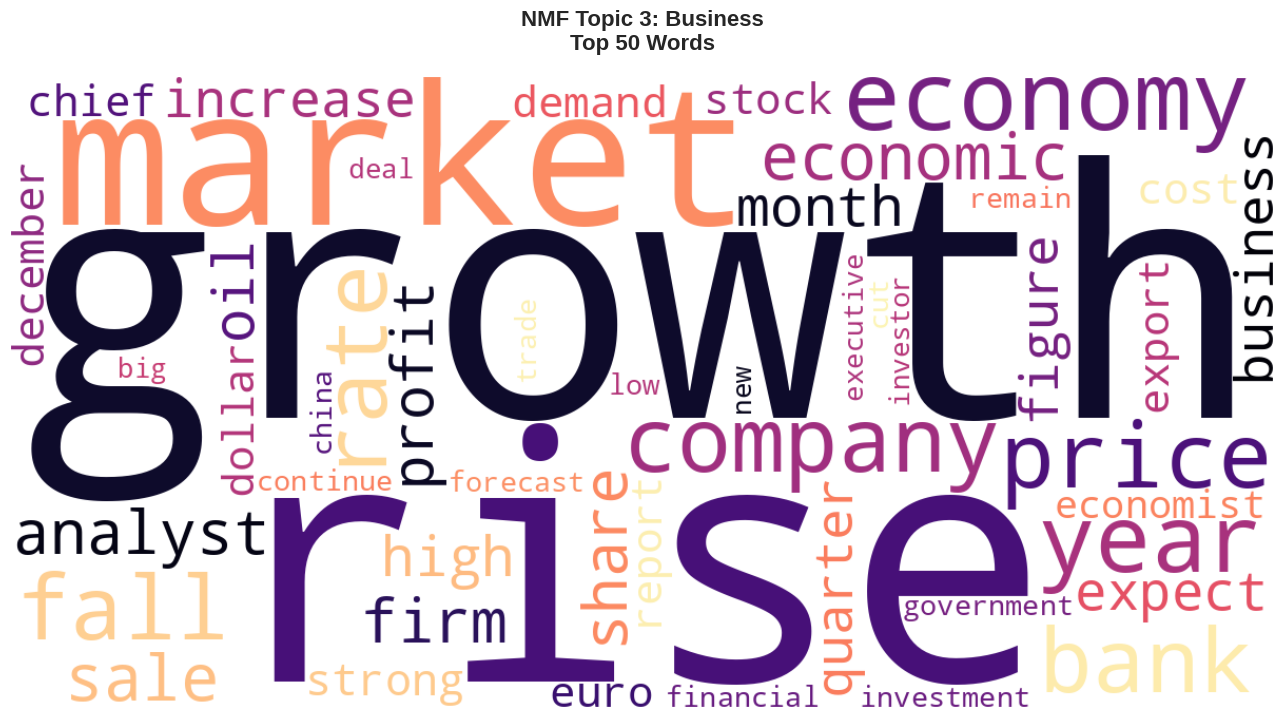

   ✅ Saved: wordclouds/nmf_topic_4.png


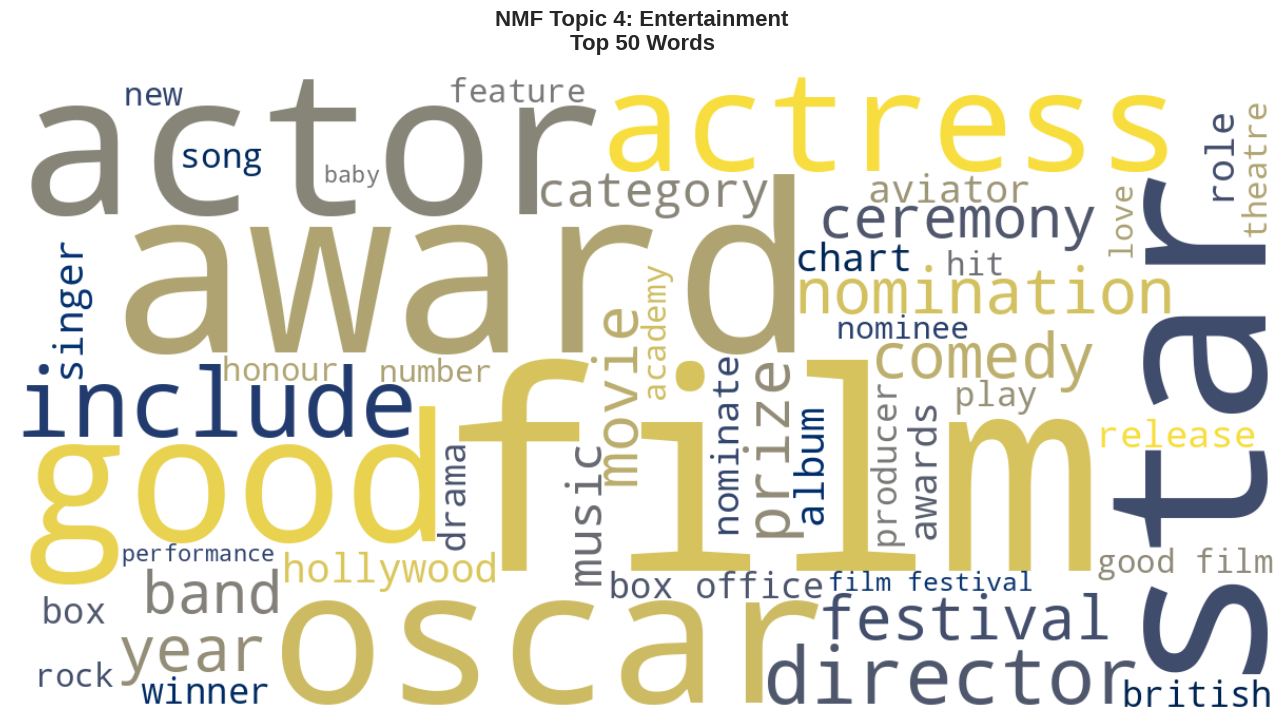


📊 COMBINED WORD CLOUD GRID

🎨 Creating combined visualization for NMF topics...



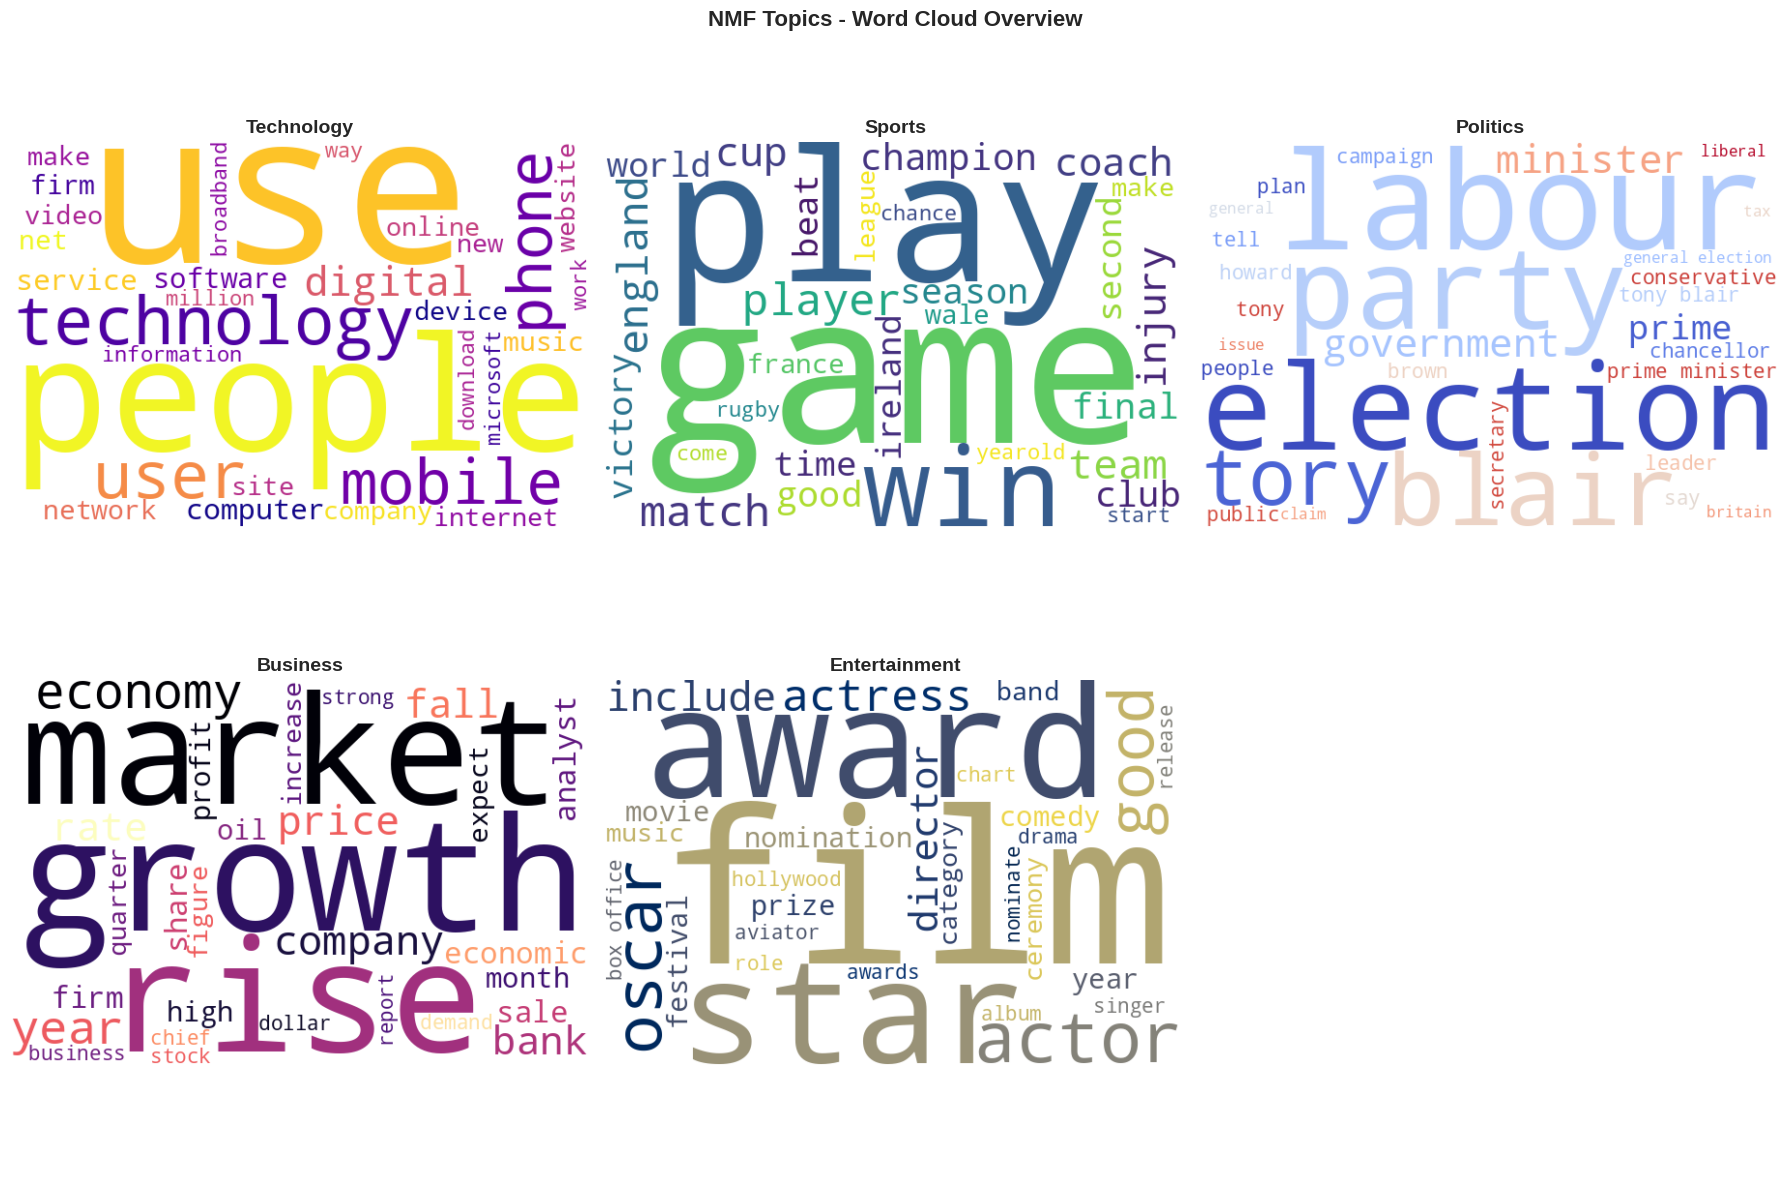


✅ WORD CLOUD GENERATION COMPLETED
💾 All images saved to: wordclouds/


In [11]:
"""
Step 9: Word Cloud Visualizations

This cell creates word clouds for each topic from both LDA and NMF models.
"""

from wordcloud import WordCloud
import matplotlib.pyplot as plt
import os
import warnings

# ============================================
# 🛠️ UYARI GİZLEYİCİ (O kırmızı yazıları susturuyoruz)
# ============================================
warnings.filterwarnings("ignore", category=DeprecationWarning)
# Matplotlib'in spesifik uyarısını da gizleyelim
import matplotlib.cbook
warnings.filterwarnings("ignore", module="matplotlib")

print("="*60)
print("☁️  CREATING WORD CLOUD VISUALIZATIONS")
print("="*60)

# Create output directory for saving word clouds
output_dir = 'wordclouds'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)
    print(f"✅ Created directory: {output_dir}/")

# ============================================
# HELPER FUNCTION: CREATE WORD CLOUD
# ============================================

def create_wordcloud(model, feature_names, topic_idx, topic_label, 
                     n_words=50, colormap='viridis', save_path=None):
    """
    Create and display a word cloud for a specific topic
    """
    # Get word weights for the topic
    topic = model.components_[topic_idx]
    
    # Get top N words and their weights (En önemli kelimeleri seç)
    top_indices = topic.argsort()[-n_words:][::-1]
    words = [feature_names[i] for i in top_indices]
    weights = [topic[i] for i in top_indices]
    
    # Create word frequency dictionary (Kelimeleri puanlarıyla eşleştir)
    word_freq = dict(zip(words, weights))
    
    # Generate word cloud (Ressama çizdir)
    wordcloud = WordCloud(
        width=1200,
        height=600,
        background_color='white',
        colormap=colormap,
        relative_scaling=0.5,
        min_font_size=10,
        max_words=n_words,
        prefer_horizontal=0.7
    ).generate_from_frequencies(word_freq)
    
    # Create figure (Çerçevele ve göster)
    plt.figure(figsize=(14, 7))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'{topic_label}\nTop {n_words} Words', 
              fontsize=16, fontweight='bold', pad=20)
    plt.tight_layout(pad=0)
    
    # Save if path provided (Kaydet)
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f"   ✅ Saved: {save_path}")
    
    plt.show()

# ============================================
# LDA WORD CLOUDS
# ============================================

print("\n" + "="*60)
print("☁️  LDA TOPIC WORD CLOUDS")
print("="*60)

colormaps_lda = ['Blues', 'Greens', 'Reds', 'Purples', 'Oranges']

print("\n🎨 Generating word clouds for LDA topics...\n")

for i in range(N_TOPICS_LDA):
    # Mapping hatası olmaması için güvenli etiket alma
    try:
        topic_label = lda_topic_labels[i]
    except:
        topic_label = f"Topic {i}"
        
    colormap = colormaps_lda[i % len(colormaps_lda)]
    save_path = os.path.join(output_dir, f'lda_topic_{i}.png')
    
    create_wordcloud(
        model=lda_model,
        feature_names=count_feature_names,
        topic_idx=i,
        topic_label=f'LDA Topic {i}: {topic_label}',
        n_words=50,
        colormap=colormap,
        save_path=save_path
    )

# ============================================
# NMF WORD CLOUDS
# ============================================

print("\n" + "="*60)
print("☁️  NMF TOPIC WORD CLOUDS")
print("="*60)

colormaps_nmf = ['plasma', 'viridis', 'coolwarm', 'magma', 'cividis']

print("\n🎨 Generating word clouds for NMF topics...\n")

for i in range(N_TOPICS_NMF):
    # Mapping hatası olmaması için güvenli etiket alma
    try:
        topic_label = nmf_topic_labels[i]
    except:
        topic_label = f"Topic {i}"

    colormap = colormaps_nmf[i % len(colormaps_nmf)]
    save_path = os.path.join(output_dir, f'nmf_topic_{i}.png')
    
    create_wordcloud(
        model=nmf_model,
        feature_names=tfidf_feature_names,
        topic_idx=i,
        topic_label=f'NMF Topic {i}: {topic_label}',
        n_words=50,
        colormap=colormap,
        save_path=save_path
    )

# ============================================
# COMBINED VISUALIZATION (GRID)
# ============================================

print("\n" + "="*60)
print("📊 COMBINED WORD CLOUD GRID")
print("="*60)

# NMF için toplu bakış (Genelde NMF daha temiz olduğu için onu çiziyoruz)
print("\n🎨 Creating combined visualization for NMF topics...\n")

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i in range(N_TOPICS_NMF):
    # Get topic data
    topic = nmf_model.components_[i]
    top_indices = topic.argsort()[-30:][::-1]
    words = [tfidf_feature_names[idx] for idx in top_indices]
    weights = [topic[idx] for idx in top_indices]
    word_freq = dict(zip(words, weights))
    
    try:
        label = nmf_topic_labels[i]
    except:
        label = f"Topic {i}"

    # Generate word cloud
    wordcloud = WordCloud(
        width=600,
        height=400,
        background_color='white',
        colormap=colormaps_nmf[i % len(colormaps_nmf)],
        relative_scaling=0.5
    ).generate_from_frequencies(word_freq)
    
    # Display
    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].axis('off')
    axes[i].set_title(f'{label}', fontsize=14, fontweight='bold')

# Hide extra subplot if any
if N_TOPICS_NMF < 6:
    for j in range(N_TOPICS_NMF, 6):
        axes[j].axis('off')

plt.suptitle('NMF Topics - Word Cloud Overview', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'nmf_all_topics_grid.png'), 
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("\n" + "="*60)
print("✅ WORD CLOUD GENERATION COMPLETED")
print("="*60)
print(f"💾 All images saved to: {output_dir}/")

📊 CREATING BAR CHART VISUALIZATIONS
✅ Created directory: bar_charts/

📊 LDA TOPIC BAR CHARTS

📈 Creating bar charts for LDA topics...


Topic 0: Politics
   ✅ Saved: bar_charts/lda_topic_0_Politics_bar.png


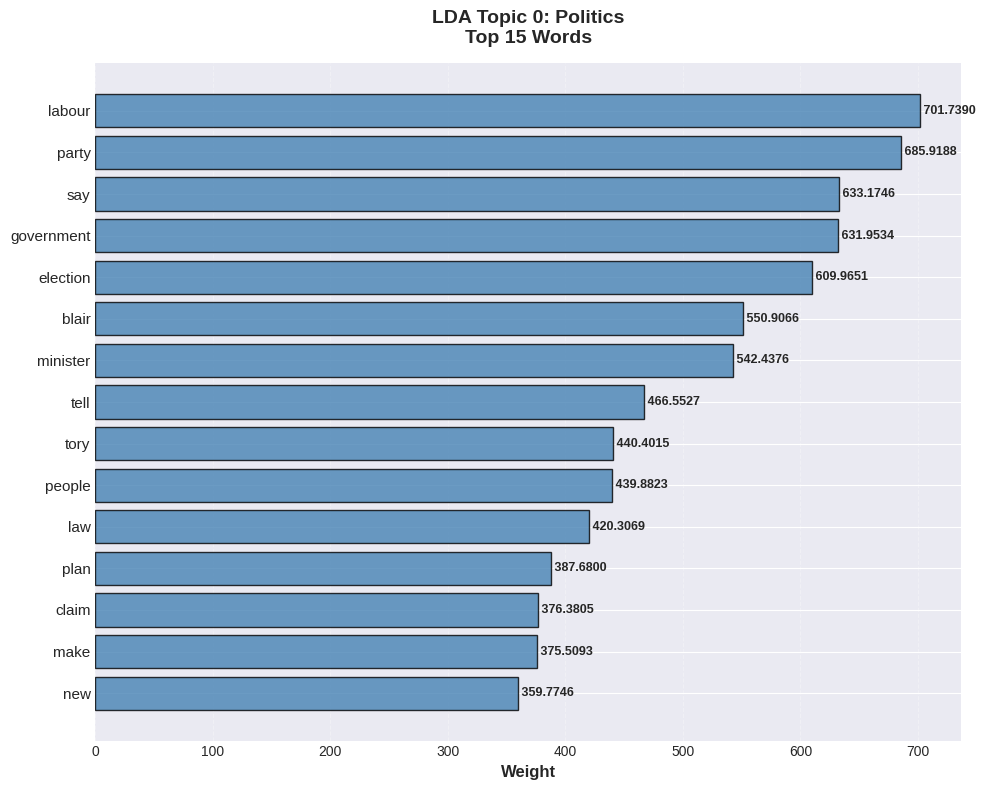


Topic 1: Technology
   ✅ Saved: bar_charts/lda_topic_1_Technology_bar.png


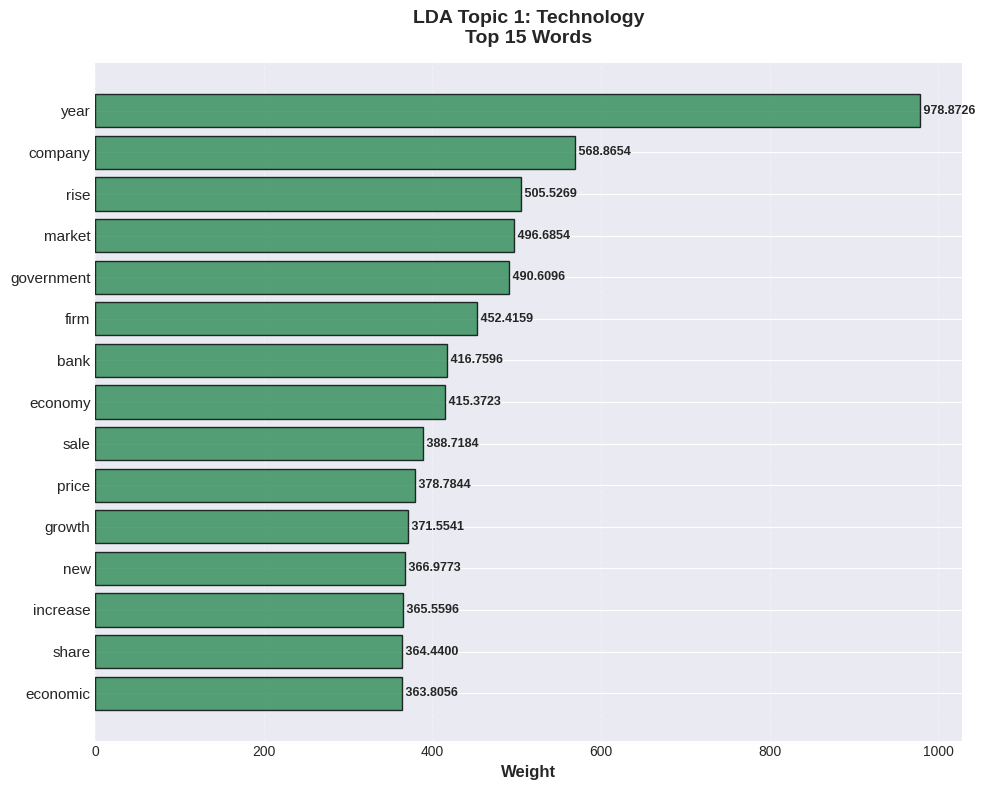


Topic 2: Sports
   ✅ Saved: bar_charts/lda_topic_2_Sports_bar.png


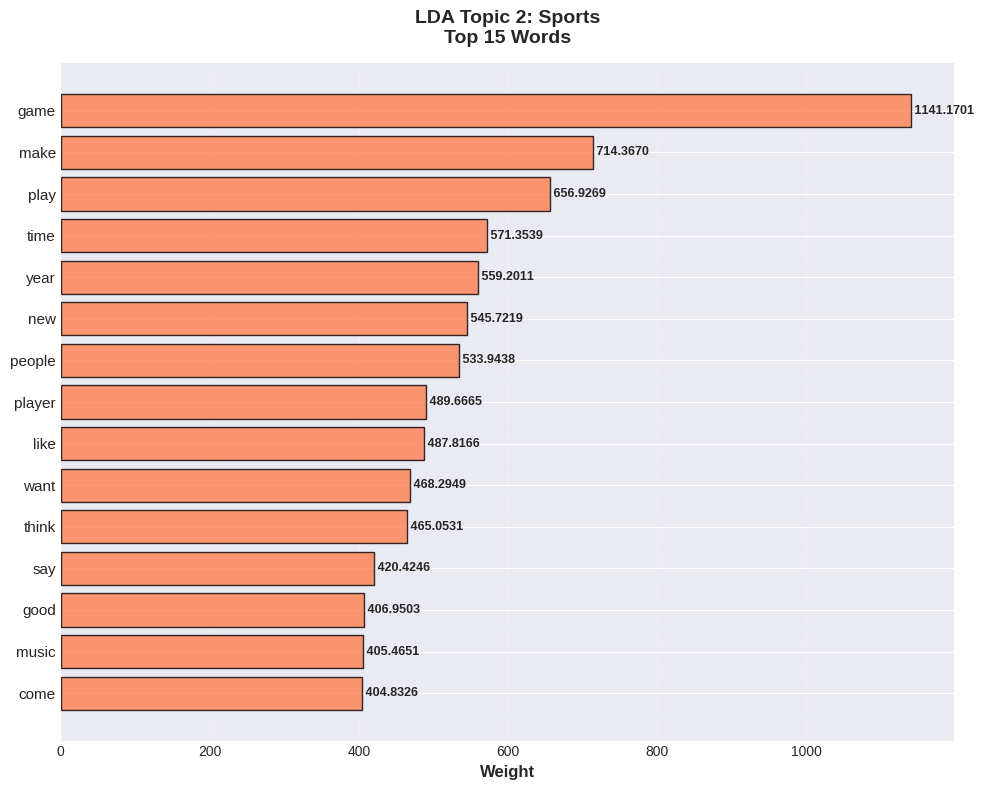


Topic 3: Entertainment
   ✅ Saved: bar_charts/lda_topic_3_Entertainment_bar.png


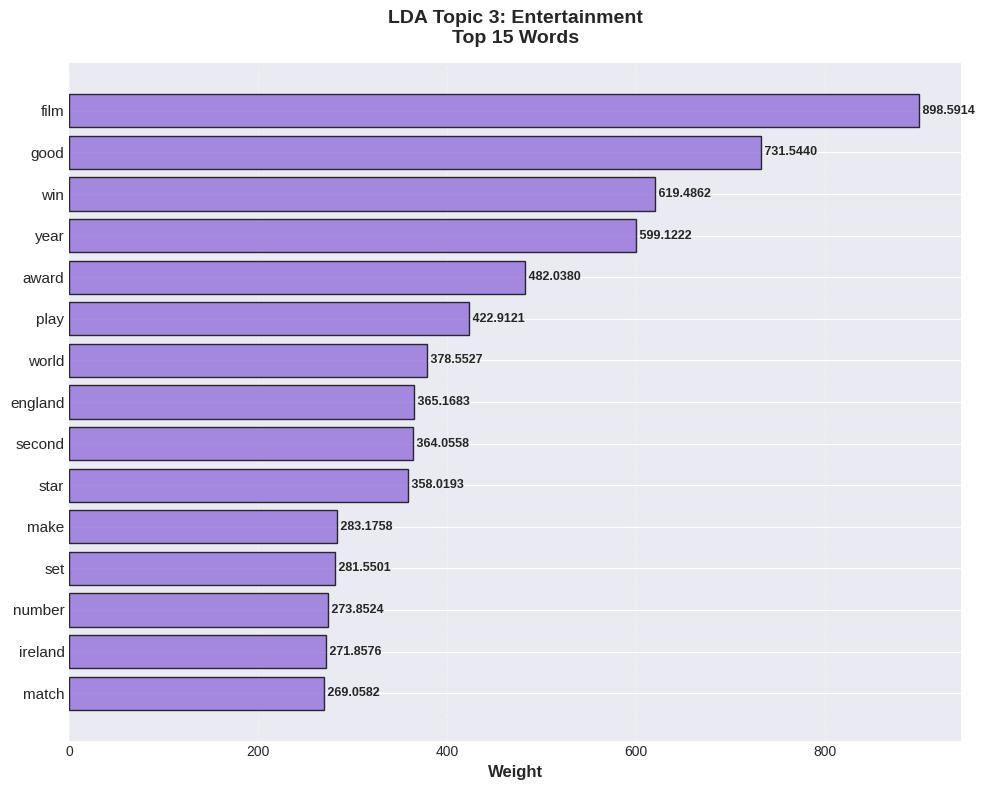


Topic 4: Business
   ✅ Saved: bar_charts/lda_topic_4_Business_bar.png


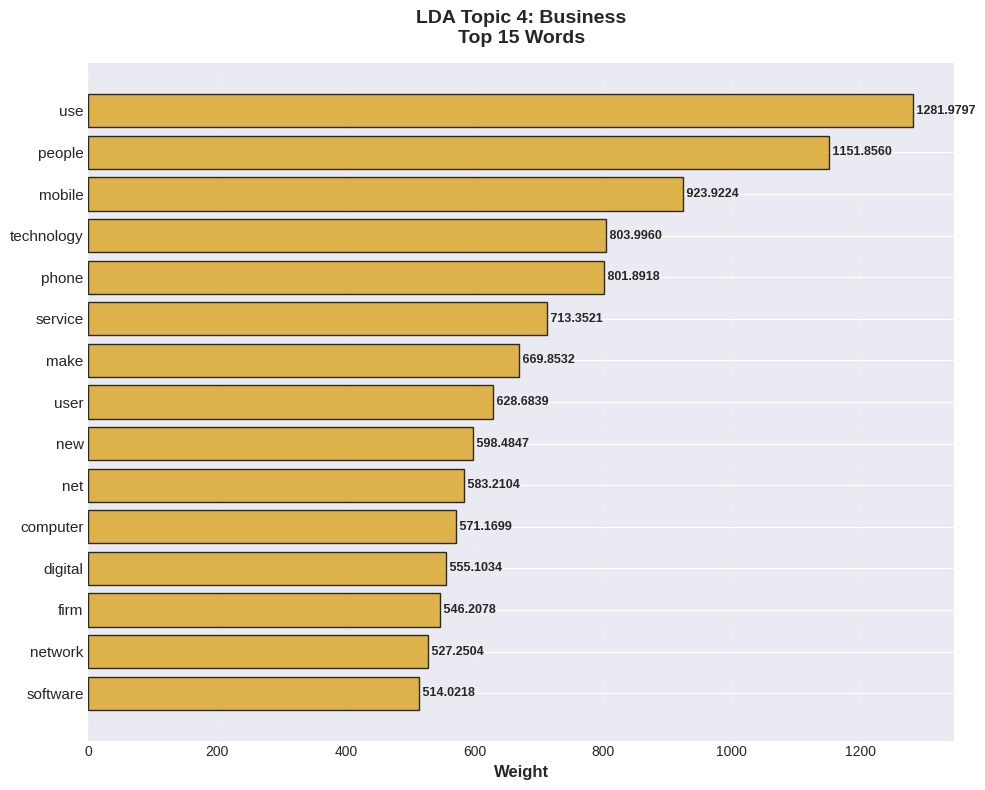


📊 NMF TOPIC BAR CHARTS

📈 Creating bar charts for NMF topics...


Topic 0: Technology
   ✅ Saved: bar_charts/nmf_topic_0_Technology_bar.png


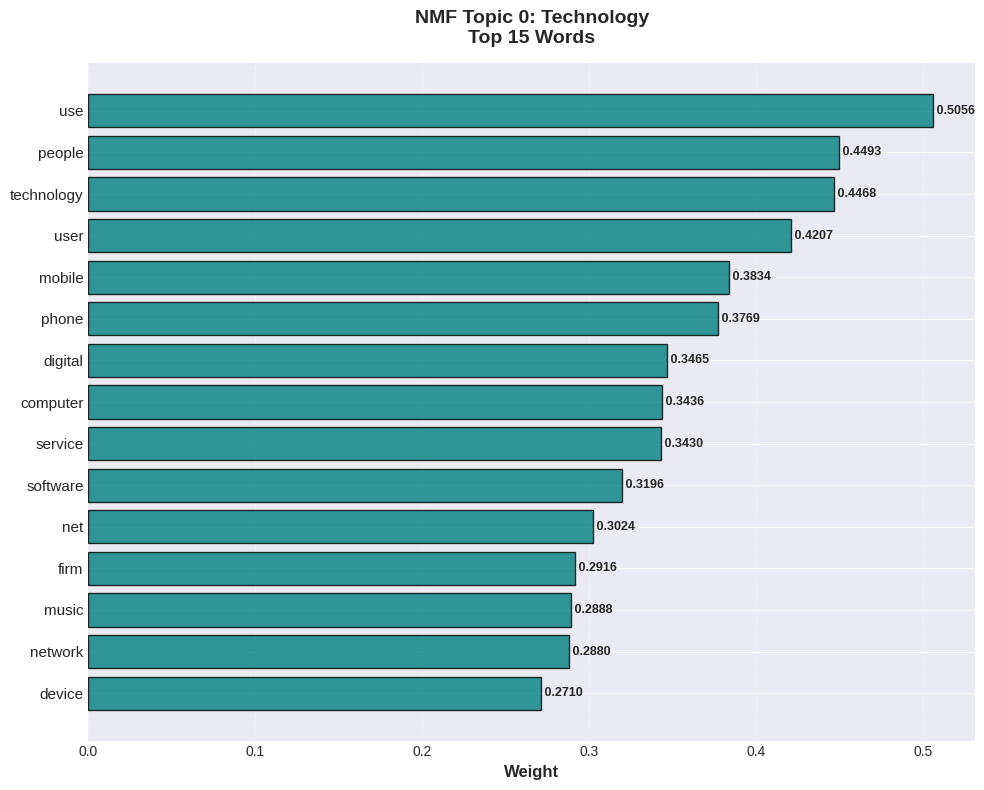


Topic 1: Sports
   ✅ Saved: bar_charts/nmf_topic_1_Sports_bar.png


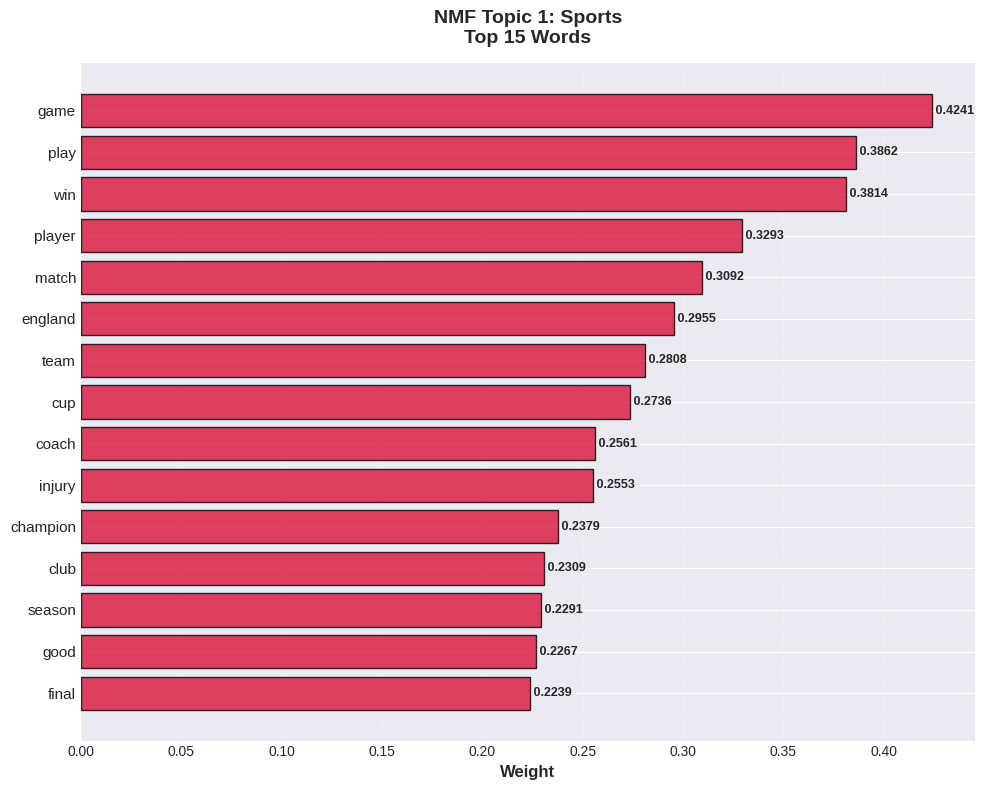


Topic 2: Politics
   ✅ Saved: bar_charts/nmf_topic_2_Politics_bar.png


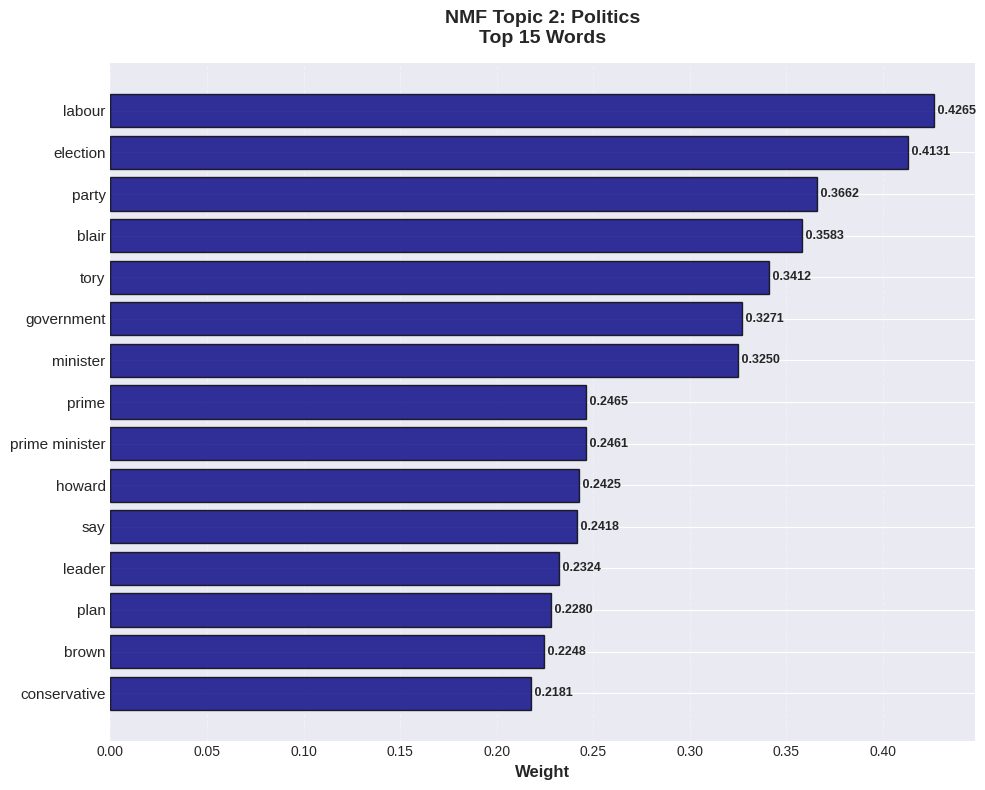


Topic 3: Business
   ✅ Saved: bar_charts/nmf_topic_3_Business_bar.png


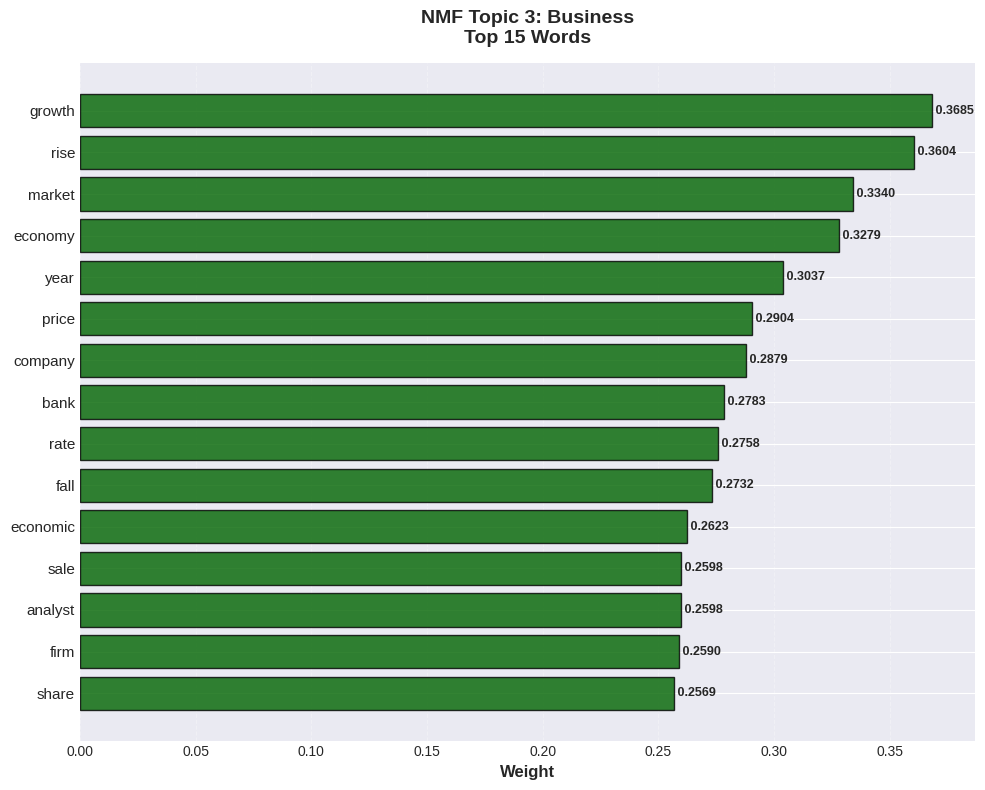


Topic 4: Entertainment
   ✅ Saved: bar_charts/nmf_topic_4_Entertainment_bar.png


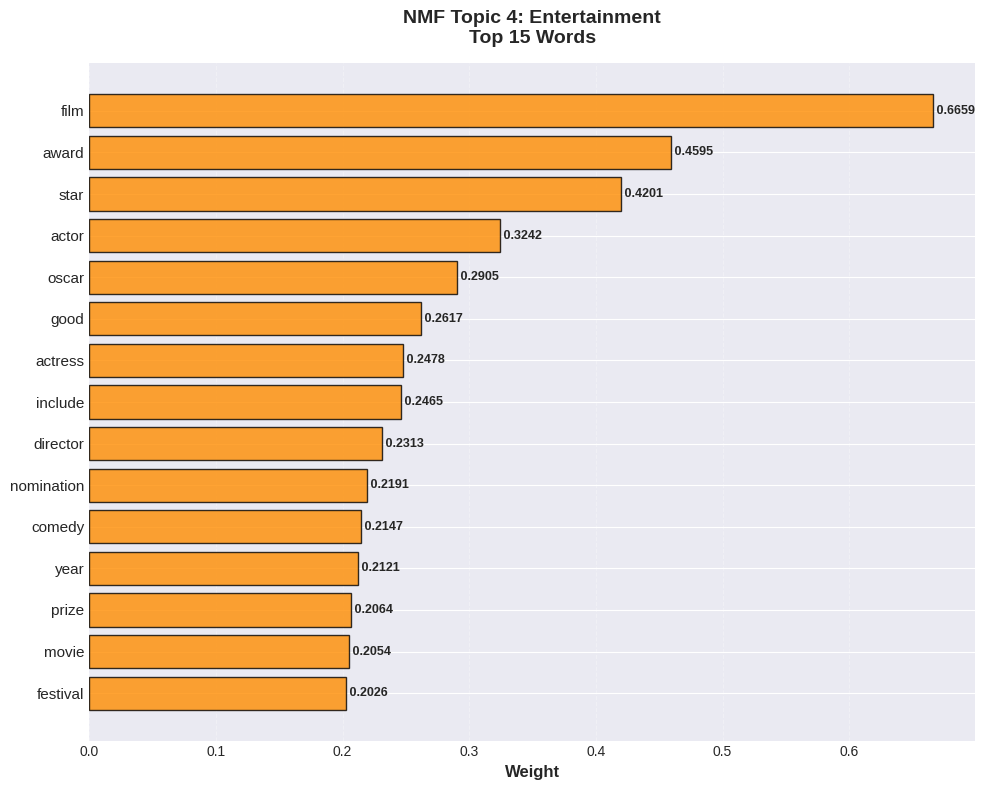


📊 COMBINED BAR CHART GRID (LDA)


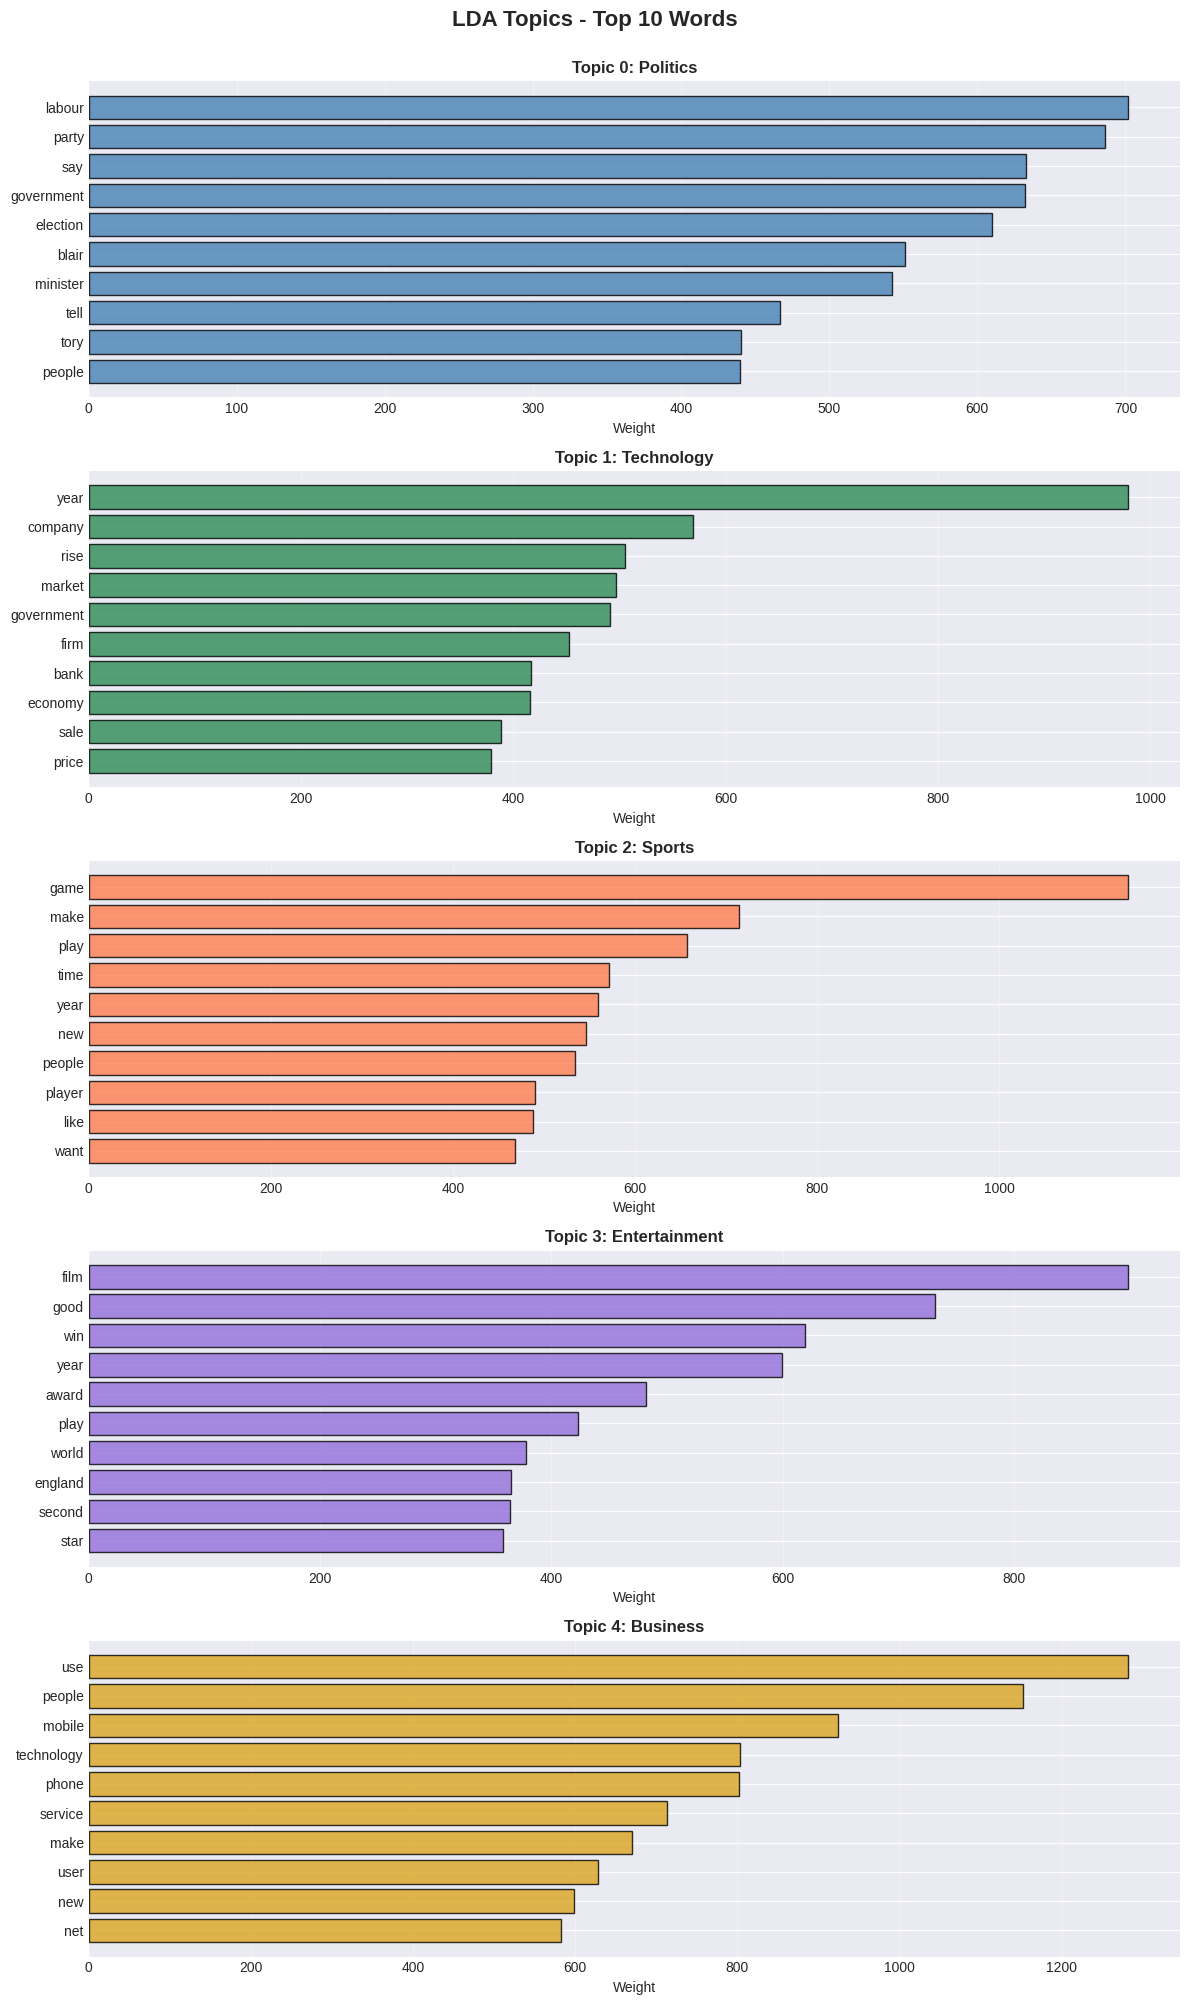

✅ Saved combined LDA bar chart

📊 COMBINED BAR CHART GRID (NMF)


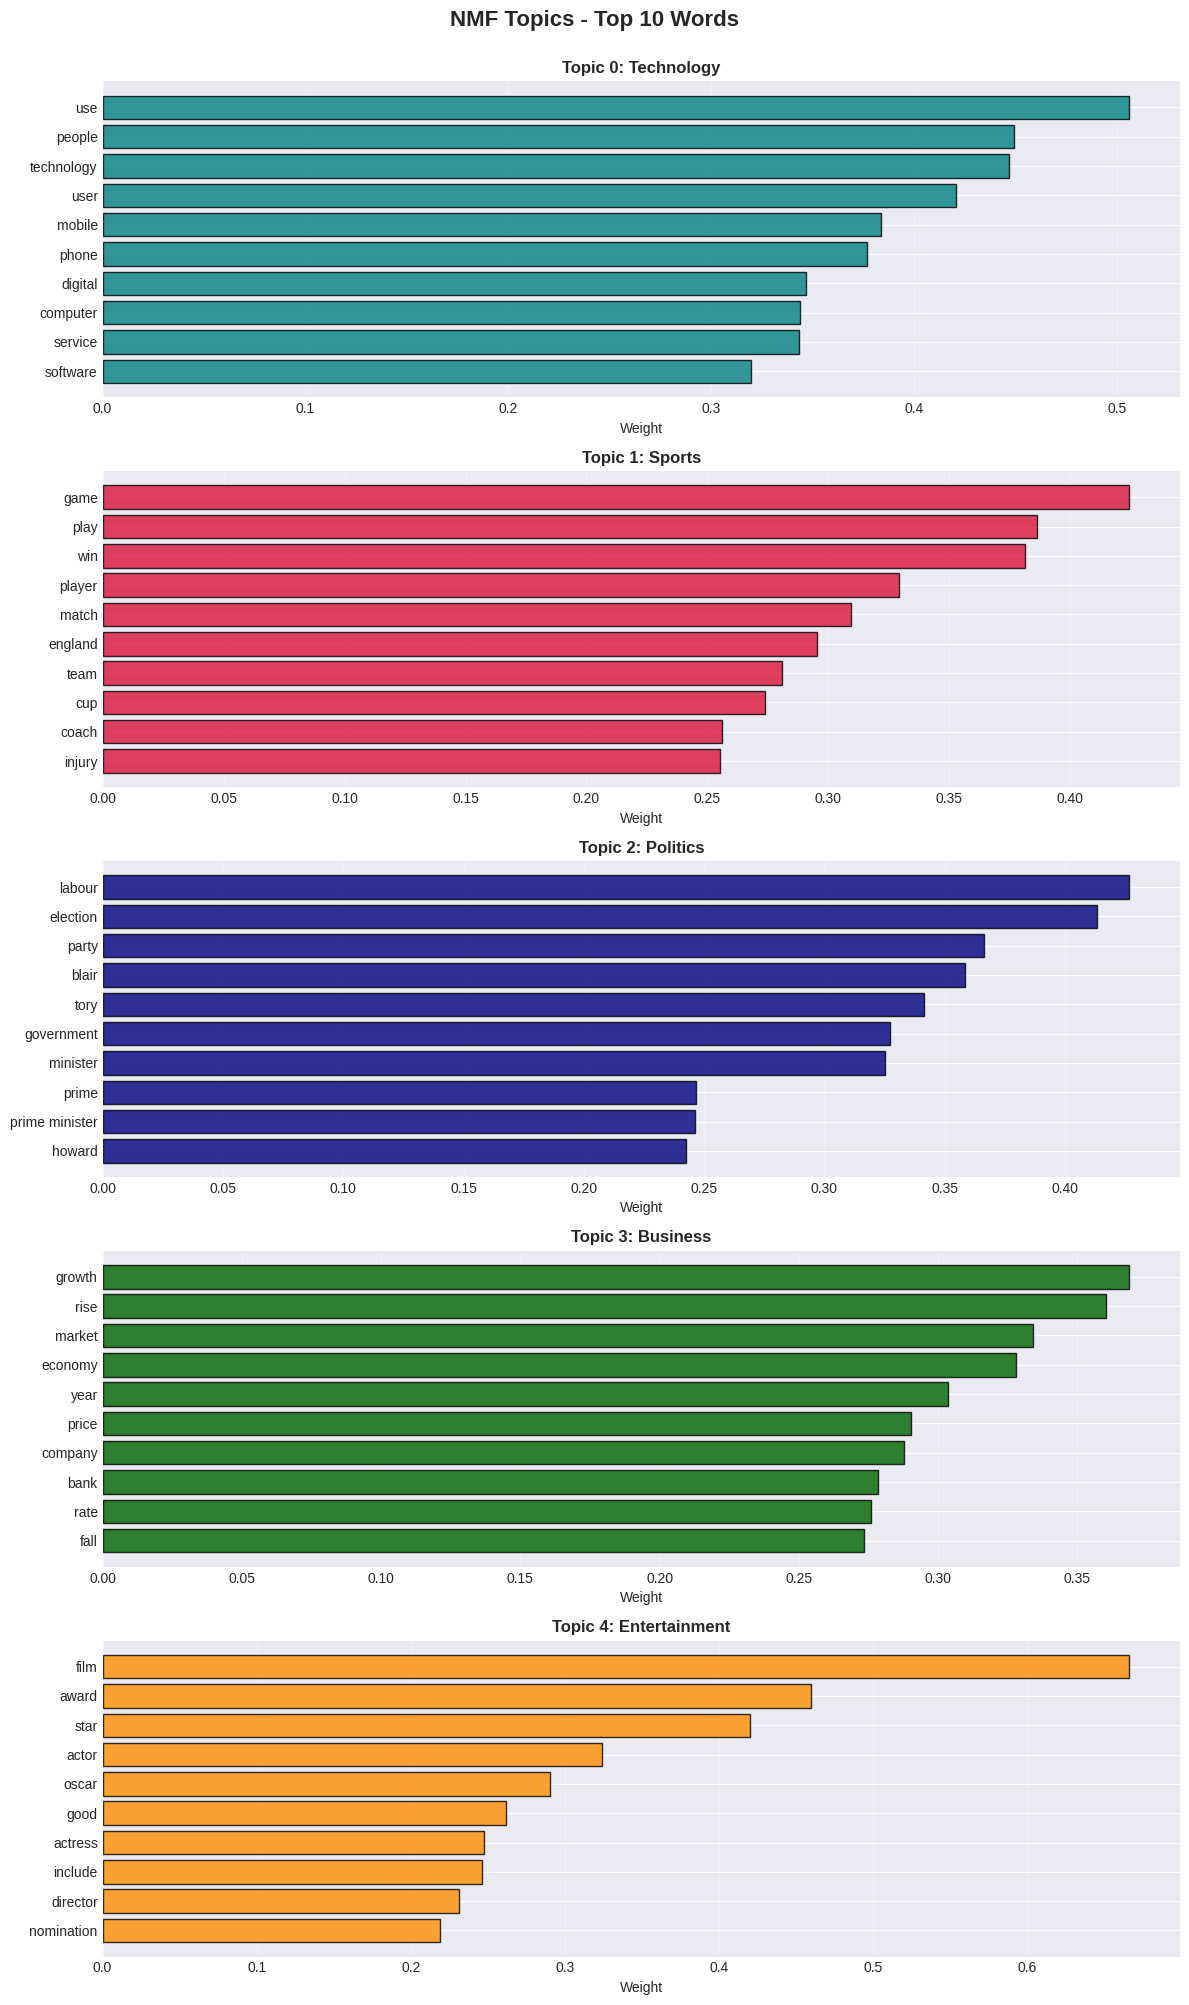

✅ Saved combined NMF bar chart

⚖️  LDA vs NMF COMPARISON CHARTS

📊 Creating side-by-side comparison for each topic...

✅ Saved: comparison_topic_0.png


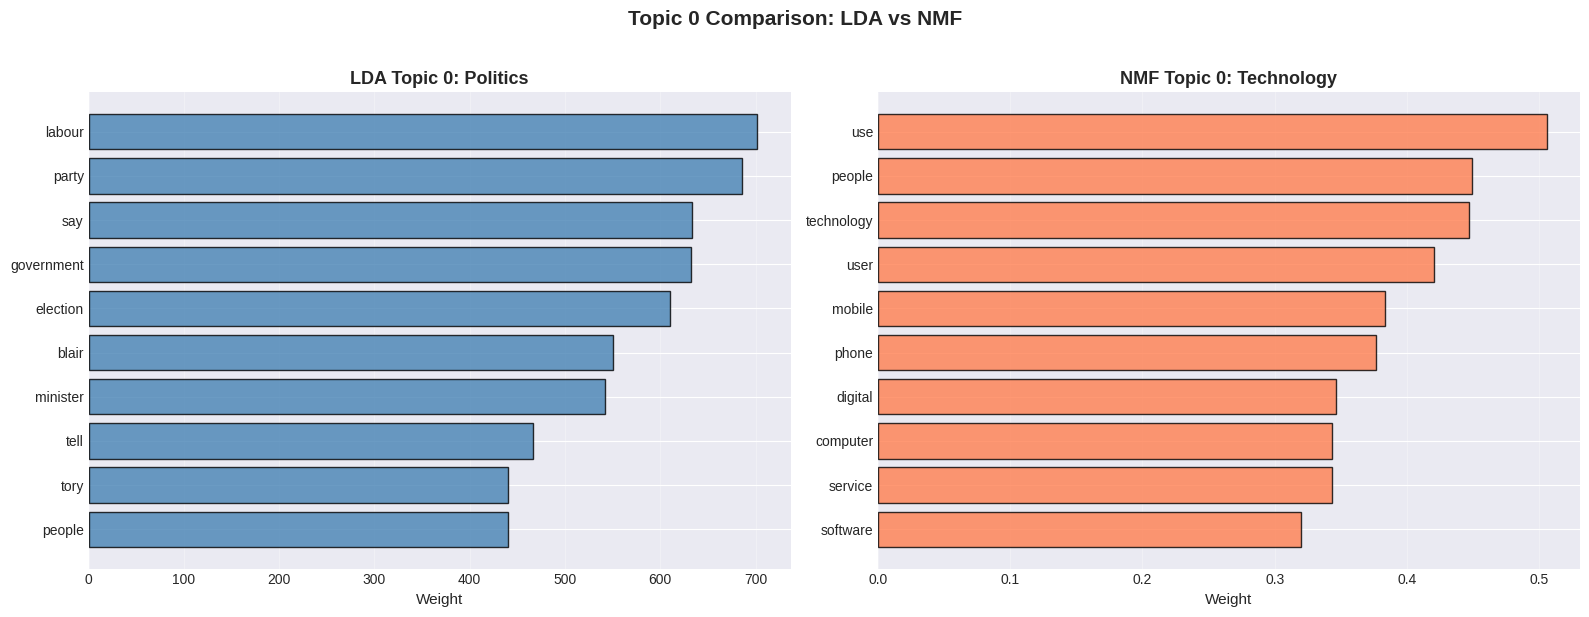

✅ Saved: comparison_topic_1.png


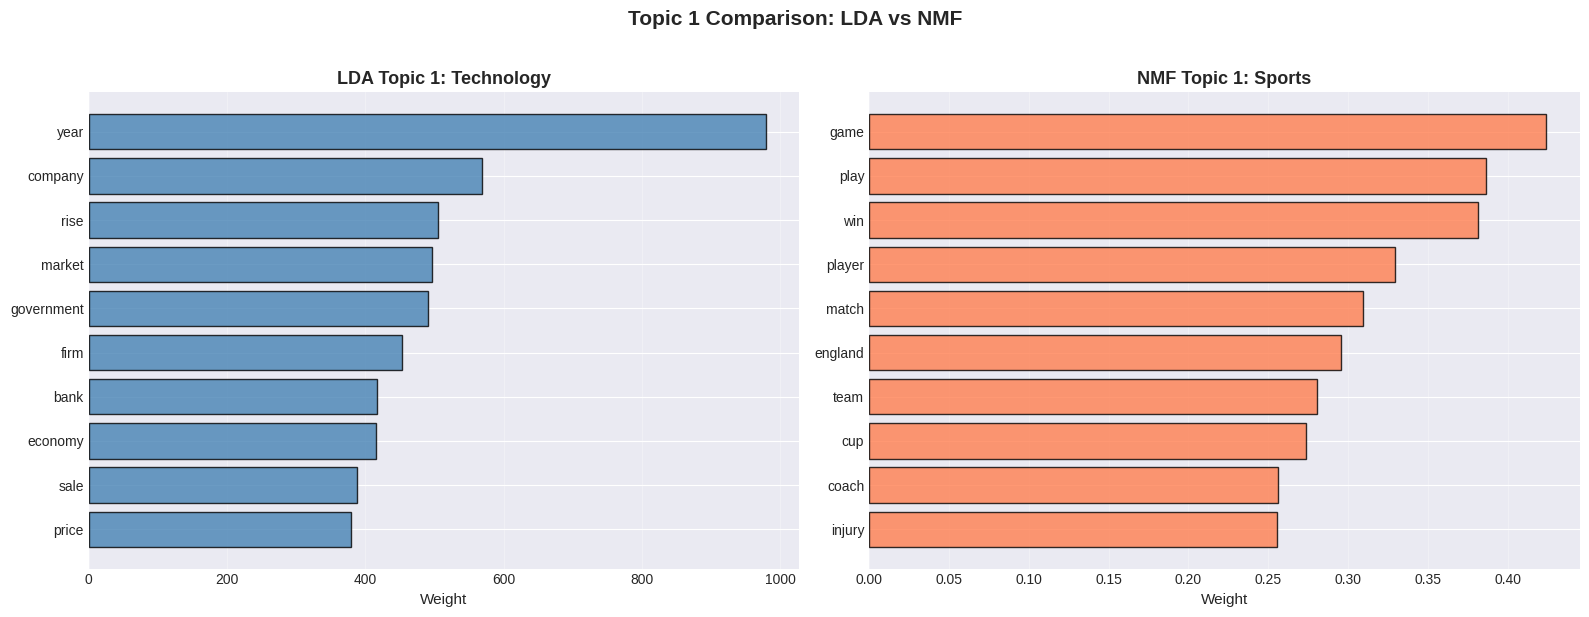

✅ Saved: comparison_topic_2.png


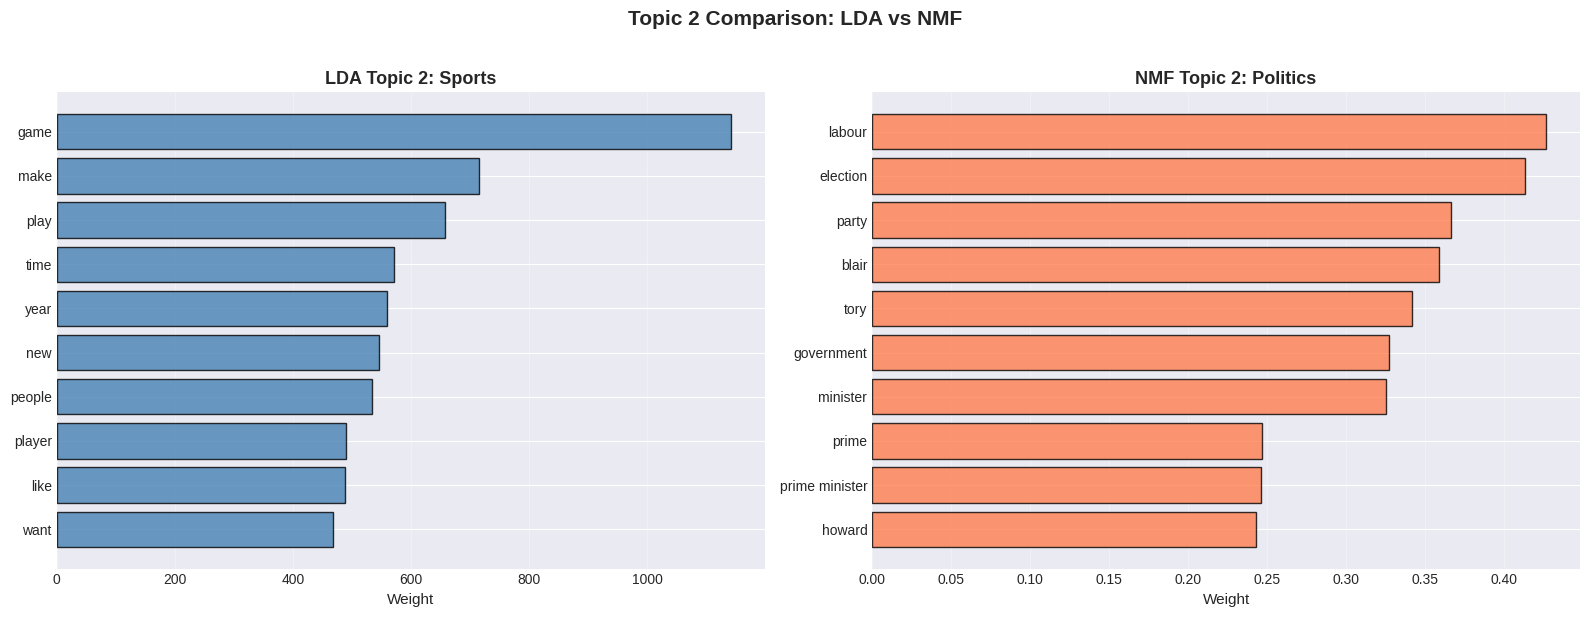

✅ Saved: comparison_topic_3.png


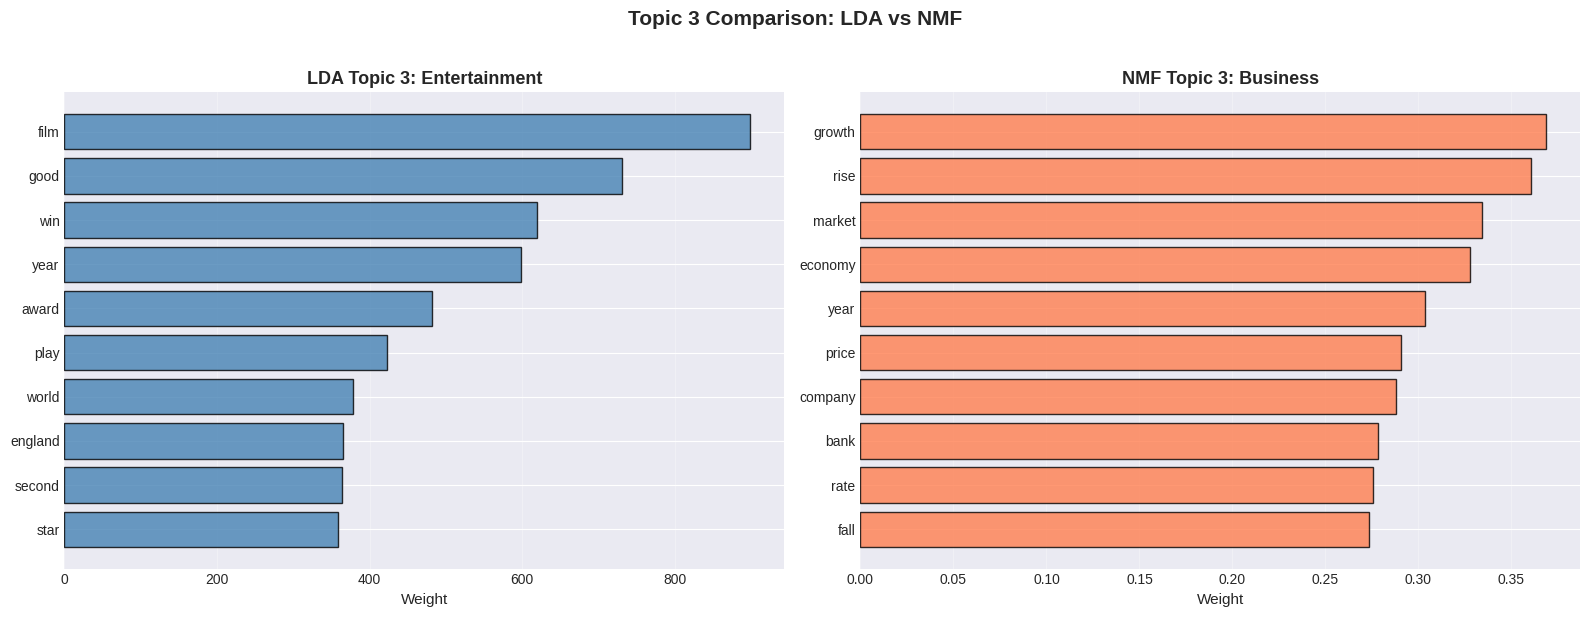

✅ Saved: comparison_topic_4.png


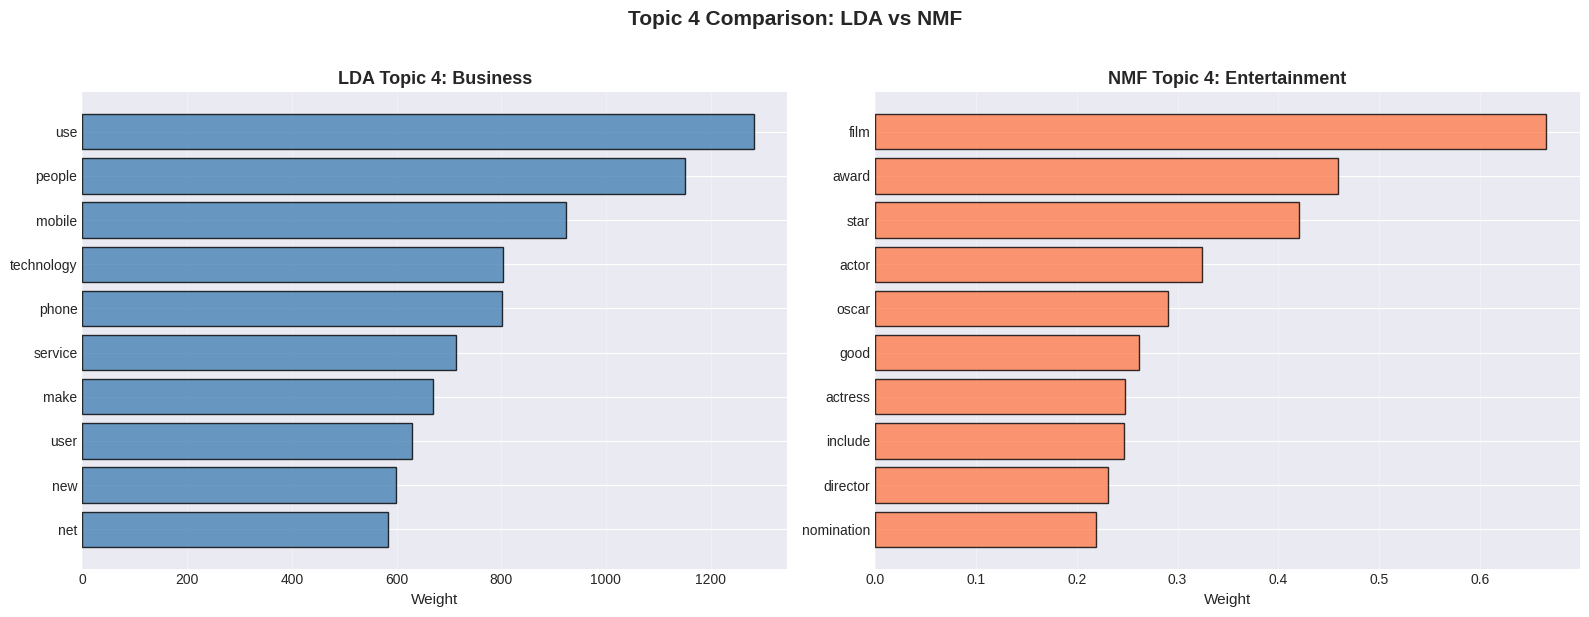


✅ BAR CHART VISUALIZATION COMPLETED

📊 Generated Visualizations:
   LDA Individual Charts: 5
   NMF Individual Charts: 5
   Combined Grids: 2 (LDA + NMF)
   Comparison Charts: 5

💾 All charts saved in: bar_charts/

💡 Bar Chart Benefits:
   ✓ Precise weight values visible
   ✓ Easy to compare word importance
   ✓ Better for detailed analysis than word clouds
   ✓ Suitable for presentations and reports


In [12]:
"""
Step 10: Topic Bar Chart Visualizations

This cell creates horizontal bar charts showing top words for each topic
with their weights/probabilities for both LDA and NMF models.
"""

print("="*60)
print("📊 CREATING BAR CHART VISUALIZATIONS")
print("="*60)

# Create output directory
bar_chart_dir = 'bar_charts'
if not os.path.exists(bar_chart_dir):
    os.makedirs(bar_chart_dir)
    print(f"✅ Created directory: {bar_chart_dir}/")

# ============================================
# HELPER FUNCTION: CREATE BAR CHART
# ============================================

def create_topic_barchart(model, feature_names, topic_idx, topic_label,
                           n_words=15, color='steelblue', save_path=None):
    """
    Create horizontal bar chart for top words in a topic
    
    Args:
        model: Trained topic model
        feature_names: List of feature names
        topic_idx: Index of topic
        topic_label: Human-readable label
        n_words: Number of top words to display
        color: Bar color
        save_path: Path to save figure
    """
    # Get topic weights
    topic = model.components_[topic_idx]
    
    # Get top N words
    top_indices = topic.argsort()[-n_words:][::-1]
    top_words = [feature_names[i] for i in top_indices]
    top_weights = [topic[i] for i in top_indices]
    
    # Create horizontal bar chart
    fig, ax = plt.subplots(figsize=(10, 8))
    
    y_pos = np.arange(len(top_words))
    ax.barh(y_pos, top_weights, color=color, edgecolor='black', alpha=0.8)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(top_words, fontsize=11)
    ax.invert_yaxis()  # Highest value at top
    ax.set_xlabel('Weight', fontsize=12, fontweight='bold')
    ax.set_title(f'{topic_label}\nTop {n_words} Words', 
                 fontsize=14, fontweight='bold', pad=15)
    ax.grid(axis='x', alpha=0.3, linestyle='--')
    
    # Add value labels on bars
    for i, (word, weight) in enumerate(zip(top_words, top_weights)):
        ax.text(weight, i, f' {weight:.4f}', 
                va='center', fontsize=9, fontweight='bold')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f"   ✅ Saved: {save_path}")
    
    plt.show()

# ============================================
# LDA BAR CHARTS
# ============================================

print("\n" + "="*60)
print("📊 LDA TOPIC BAR CHARTS")
print("="*60)

colors_lda = ['steelblue', 'seagreen', 'coral', 'mediumpurple', 'goldenrod']

print("\n📈 Creating bar charts for LDA topics...\n")

for i in range(N_TOPICS_LDA):
    topic_label = lda_topic_labels[i]
    color = colors_lda[i % len(colors_lda)]
    save_path = os.path.join(bar_chart_dir, 
                             f'lda_topic_{i}_{topic_label.replace(" ", "_")}_bar.png')
    
    print(f"\n{'='*60}")
    print(f"Topic {i}: {topic_label}")
    print('='*60)
    
    create_topic_barchart(
        model=lda_model,
        feature_names=count_feature_names,
        topic_idx=i,
        topic_label=f'LDA Topic {i}: {topic_label}',
        n_words=15,
        color=color,
        save_path=save_path
    )

# ============================================
# NMF BAR CHARTS
# ============================================

print("\n" + "="*60)
print("📊 NMF TOPIC BAR CHARTS")
print("="*60)

colors_nmf = ['teal', 'crimson', 'navy', 'darkgreen', 'darkorange']

print("\n📈 Creating bar charts for NMF topics...\n")

for i in range(N_TOPICS_NMF):
    topic_label = nmf_topic_labels[i]
    color = colors_nmf[i % len(colors_nmf)]
    save_path = os.path.join(bar_chart_dir, 
                             f'nmf_topic_{i}_{topic_label.replace(" ", "_")}_bar.png')
    
    print(f"\n{'='*60}")
    print(f"Topic {i}: {topic_label}")
    print('='*60)
    
    create_topic_barchart(
        model=nmf_model,
        feature_names=tfidf_feature_names,
        topic_idx=i,
        topic_label=f'NMF Topic {i}: {topic_label}',
        n_words=15,
        color=color,
        save_path=save_path
    )

# ============================================
# COMBINED GRID VISUALIZATION
# ============================================

print("\n" + "="*60)
print("📊 COMBINED BAR CHART GRID (LDA)")
print("="*60)

fig, axes = plt.subplots(N_TOPICS_LDA, 1, figsize=(12, 4 * N_TOPICS_LDA))

if N_TOPICS_LDA == 1:
    axes = [axes]

for i in range(N_TOPICS_LDA):
    topic = lda_model.components_[i]
    top_indices = topic.argsort()[-10:][::-1]
    top_words = [count_feature_names[idx] for idx in top_indices]
    top_weights = [topic[idx] for idx in top_indices]
    
    axes[i].barh(range(len(top_words)), top_weights, 
                 color=colors_lda[i % len(colors_lda)], 
                 edgecolor='black', alpha=0.8)
    axes[i].set_yticks(range(len(top_words)))
    axes[i].set_yticklabels(top_words)
    axes[i].invert_yaxis()
    axes[i].set_xlabel('Weight', fontsize=10)
    axes[i].set_title(f'Topic {i}: {lda_topic_labels[i]}', 
                      fontsize=12, fontweight='bold')
    axes[i].grid(axis='x', alpha=0.3)

plt.suptitle('LDA Topics - Top 10 Words', fontsize=16, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(bar_chart_dir, 'lda_all_topics_bars.png'),
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("✅ Saved combined LDA bar chart")

# ============================================
# COMBINED GRID VISUALIZATION (NMF)
# ============================================

print("\n" + "="*60)
print("📊 COMBINED BAR CHART GRID (NMF)")
print("="*60)

fig, axes = plt.subplots(N_TOPICS_NMF, 1, figsize=(12, 4 * N_TOPICS_NMF))

if N_TOPICS_NMF == 1:
    axes = [axes]

for i in range(N_TOPICS_NMF):
    topic = nmf_model.components_[i]
    top_indices = topic.argsort()[-10:][::-1]
    top_words = [tfidf_feature_names[idx] for idx in top_indices]
    top_weights = [topic[idx] for idx in top_indices]
    
    axes[i].barh(range(len(top_words)), top_weights, 
                 color=colors_nmf[i % len(colors_nmf)], 
                 edgecolor='black', alpha=0.8)
    axes[i].set_yticks(range(len(top_words)))
    axes[i].set_yticklabels(top_words)
    axes[i].invert_yaxis()
    axes[i].set_xlabel('Weight', fontsize=10)
    axes[i].set_title(f'Topic {i}: {nmf_topic_labels[i]}', 
                      fontsize=12, fontweight='bold')
    axes[i].grid(axis='x', alpha=0.3)

plt.suptitle('NMF Topics - Top 10 Words', fontsize=16, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(bar_chart_dir, 'nmf_all_topics_bars.png'),
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("✅ Saved combined NMF bar chart")

# ============================================
# SIDE-BY-SIDE COMPARISON
# ============================================

print("\n" + "="*60)
print("⚖️  LDA vs NMF COMPARISON CHARTS")
print("="*60)

print("\n📊 Creating side-by-side comparison for each topic...\n")

for i in range(min(N_TOPICS_LDA, N_TOPICS_NMF)):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # LDA
    topic_lda = lda_model.components_[i]
    top_indices_lda = topic_lda.argsort()[-10:][::-1]
    top_words_lda = [count_feature_names[idx] for idx in top_indices_lda]
    top_weights_lda = [topic_lda[idx] for idx in top_indices_lda]
    
    ax1.barh(range(len(top_words_lda)), top_weights_lda, 
             color='steelblue', edgecolor='black', alpha=0.8)
    ax1.set_yticks(range(len(top_words_lda)))
    ax1.set_yticklabels(top_words_lda)
    ax1.invert_yaxis()
    ax1.set_xlabel('Weight', fontsize=11)
    ax1.set_title(f'LDA Topic {i}: {lda_topic_labels[i]}', 
                  fontsize=13, fontweight='bold')
    ax1.grid(axis='x', alpha=0.3)
    
    # NMF
    topic_nmf = nmf_model.components_[i]
    top_indices_nmf = topic_nmf.argsort()[-10:][::-1]
    top_words_nmf = [tfidf_feature_names[idx] for idx in top_indices_nmf]
    top_weights_nmf = [topic_nmf[idx] for idx in top_indices_nmf]
    
    ax2.barh(range(len(top_words_nmf)), top_weights_nmf, 
             color='coral', edgecolor='black', alpha=0.8)
    ax2.set_yticks(range(len(top_words_nmf)))
    ax2.set_yticklabels(top_words_nmf)
    ax2.invert_yaxis()
    ax2.set_xlabel('Weight', fontsize=11)
    ax2.set_title(f'NMF Topic {i}: {nmf_topic_labels[i]}', 
                  fontsize=13, fontweight='bold')
    ax2.grid(axis='x', alpha=0.3)
    
    plt.suptitle(f'Topic {i} Comparison: LDA vs NMF', 
                 fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    save_path = os.path.join(bar_chart_dir, f'comparison_topic_{i}.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"✅ Saved: comparison_topic_{i}.png")
    plt.show()

# ============================================
# SUMMARY
# ============================================

print("\n" + "="*60)
print("✅ BAR CHART VISUALIZATION COMPLETED")
print("="*60)

print(f"\n📊 Generated Visualizations:")
print(f"   LDA Individual Charts: {N_TOPICS_LDA}")
print(f"   NMF Individual Charts: {N_TOPICS_NMF}")
print(f"   Combined Grids: 2 (LDA + NMF)")
print(f"   Comparison Charts: {min(N_TOPICS_LDA, N_TOPICS_NMF)}")
print(f"\n💾 All charts saved in: {bar_chart_dir}/")

print("\n💡 Bar Chart Benefits:")
print("   ✓ Precise weight values visible")
print("   ✓ Easy to compare word importance")
print("   ✓ Better for detailed analysis than word clouds")
print("   ✓ Suitable for presentations and reports")

In [13]:
"""
Step 11: Final Analysis & Comprehensive Summary Report

This cell generates a complete summary of the topic modeling project
including performance metrics, insights, and recommendations.
"""

from datetime import datetime

print("="*70)
print("📋 FINAL ANALYSIS & SUMMARY REPORT")
print("="*70)
print(f"\nGenerated on: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")

# ============================================
# 1. PROJECT OVERVIEW
# ============================================

print("="*70)
print("1️⃣  PROJECT OVERVIEW")
print("="*70)

print(f"""
📌 Project: Topic Modeling on News Articles
📌 Objective: Discover hidden thematic structures in text corpus
📌 Methods: LDA (Latent Dirichlet Allocation) & NMF (Non-Negative Matrix Factorization)

📊 Dataset Statistics:
   • Total Documents: {len(df):,}
   • Average Words per Document (Original): {df['word_count'].mean():.1f}
   • Average Words per Document (Cleaned): {df['cleaned_word_count'].mean():.1f}
   • Vocabulary Size: {len(set(' '.join(df['cleaned_text']).split())):,} unique words
   • Text Reduction: {((1 - df['cleaned_word_count'].mean() / df['word_count'].mean()) * 100):.1f}%
""")

# ============================================
# 2. PREPROCESSING SUMMARY
# ============================================

print("="*70)
print("2️⃣  PREPROCESSING SUMMARY")
print("="*70)

print("""
✅ Preprocessing Steps Applied:
   1. Lowercasing
   2. URL and email removal
   3. Punctuation and number removal
   4. Tokenization
   5. Stop-word removal (standard + custom)
   6. Lemmatization (spaCy/NLTK)
   7. Short token filtering (min 3 characters)

🔧 Configuration:
   • Lemmatization Engine: spaCy
   • Minimum Token Length: 3 characters
   • Custom Stopwords: Added domain-specific terms
""")

# ============================================
# 3. VECTORIZATION SUMMARY
# ============================================

print("="*70)
print("3️⃣  VECTORIZATION SUMMARY")
print("="*70)

print(f"""
📊 TF-IDF Vectorization (for NMF):
   • Matrix Shape: {tfidf_matrix.shape}
   • Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%
   • Max Features: {MAX_FEATURES}
   • Min Document Frequency: {MIN_DF}
   • Max Document Frequency: {MAX_DF}
   • N-gram Range: {NGRAM_RANGE}

📊 Count Vectorization (for LDA):
   • Matrix Shape: {count_matrix.shape}
   • Sparsity: {(1 - count_matrix.nnz / (count_matrix.shape[0] * count_matrix.shape[1])) * 100:.2f}%
   • Same configuration as TF-IDF
""")

# ============================================
# 4. LDA MODEL SUMMARY
# ============================================

print("="*70)
print("4️⃣  LDA MODEL SUMMARY")
print("="*70)

print(f"""
🧠 Model Configuration:
   • Number of Topics: {N_TOPICS_LDA}
   • Algorithm: Online Variational Bayes
   • Iterations: {lda_model.n_iter_}
   • Random State: {RANDOM_STATE}

📊 Performance Metrics:
   • Perplexity: {lda_model.perplexity(count_matrix):.2f}
     (Lower is better; measures how well model predicts samples)
   • Log-Likelihood: {lda_model.score(count_matrix):.2f}
     (Higher is better; model fit quality)

🏷️  Discovered Topics:
""")

for i, label in enumerate(lda_topic_labels):
    doc_count = (df['lda_dominant_topic'] == i).sum()
    percentage = (doc_count / len(df)) * 100
    top_words = ', '.join(lda_topics[i][:5])
    print(f"   Topic {i} - {label:20s}: {doc_count:4d} docs ({percentage:5.1f}%) | [{top_words}]")

avg_confidence = df['lda_topic_probability'].mean()
print(f"\n🎯 Average Topic Assignment Confidence: {avg_confidence:.3f}")

# ============================================
# 5. NMF MODEL SUMMARY
# ============================================

print("\n" + "="*70)
print("5️⃣  NMF MODEL SUMMARY")
print("="*70)

print(f"""
🧠 Model Configuration:
   • Number of Topics: {N_TOPICS_NMF}
   • Initialization: NNDSVD-a (Non-Negative Double SVD)
   • Iterations: {nmf_model.n_iter_}
   • Random State: {RANDOM_STATE}
   • Regularization: L1 + L2 (α = 0.1)

📊 Performance Metrics:
   • Reconstruction Error: {nmf_model.reconstruction_err_:.4f}
     (Lower is better; measures approximation quality)

🏷️  Discovered Topics:
""")

for i, label in enumerate(nmf_topic_labels):
    doc_count = (df['nmf_dominant_topic'] == i).sum()
    percentage = (doc_count / len(df)) * 100
    top_words = ', '.join(nmf_topics[i][:5])
    print(f"   Topic {i} - {label:20s}: {doc_count:4d} docs ({percentage:5.1f}%) | [{top_words}]")

avg_weight = df['nmf_topic_weight'].mean()
print(f"\n🎯 Average Topic Assignment Weight: {avg_weight:.3f}")

# ============================================
# 6. MODEL COMPARISON
# ============================================

print("\n" + "="*70)
print("6️⃣  LDA vs NMF COMPARISON")
print("="*70)

# Calculate agreement
agreement = (df['lda_dominant_topic'] == df['nmf_dominant_topic']).sum()
agreement_pct = (agreement / len(df)) * 100

print(f"""
⚖️  Topic Assignment Agreement:
   • Exact Match: {agreement:,} / {len(df):,} documents ({agreement_pct:.2f}%)
   
💡 Interpretation:
   • High agreement (>70%): Models converge on similar topic structure
   • Medium agreement (40-70%): Different perspectives on same data
   • Low agreement (<40%): Models capture different aspects

📊 Key Differences:
   • LDA: Probabilistic, allows topic mixing, better for overlapping topics
   • NMF: Deterministic, parts-based, better for distinct topics
   • LDA uses raw counts, NMF uses TF-IDF weights
   
🎯 Current Agreement: {agreement_pct:.1f}% - {'High' if agreement_pct > 70 else 'Medium' if agreement_pct > 40 else 'Low'}
""")

# ============================================
# 7. TOPIC QUALITY ASSESSMENT
# ============================================

print("="*70)
print("7️⃣  TOPIC QUALITY ASSESSMENT")
print("="*70)

# Calculate topic diversity
def calculate_topic_diversity(topics):
    """Calculate average unique words ratio across topics"""
    all_words = set()
    total_words = 0
    for topic in topics:
        all_words.update(topic[:10])
        total_words += 10
    return len(all_words) / total_words

lda_diversity = calculate_topic_diversity(lda_topics)
nmf_diversity = calculate_topic_diversity(nmf_topics)

print(f"""
📏 Topic Diversity Score:
   • LDA: {lda_diversity:.3f} (1.0 = completely distinct topics)
   • NMF: {nmf_diversity:.3f}
   
   Interpretation:
   - Score > 0.8: Excellent diversity, minimal overlap
   - Score 0.6-0.8: Good diversity, some overlap
   - Score < 0.6: High overlap, consider reducing topics

📊 Topic Distribution Balance:
   • LDA Entropy: {-sum((df['lda_dominant_topic'].value_counts(normalize=True) * np.log(df['lda_dominant_topic'].value_counts(normalize=True))).values):.3f}
   • NMF Entropy: {-sum((df['nmf_dominant_topic'].value_counts(normalize=True) * np.log(df['nmf_dominant_topic'].value_counts(normalize=True))).values):.3f}
   
   (Higher entropy = more balanced topic distribution)

✅ Quality Checklist:
   {'✓' if lda_diversity > 0.7 else '✗'} Topics are sufficiently diverse
   {'✓' if avg_confidence > 0.4 else '✗'} High confidence in assignments
   {'✓' if df['lda_dominant_topic'].nunique() == N_TOPICS_LDA else '✗'} All topics are used
   {'✓' if df['lda_topic_probability'].std() < 0.3 else '✗'} Consistent assignment confidence
""")

# ============================================
# 8. VISUALIZATIONS GENERATED
# ============================================

print("="*70)
print("8️⃣  GENERATED VISUALIZATIONS")
print("="*70)

print(f"""
📊 Visualization Outputs:

1. Interactive Visualization:
   ✓ pyLDAvis HTML file: lda_visualization.html
   
2. Word Clouds ({N_TOPICS_LDA + N_TOPICS_NMF + 2} files):
   ✓ {N_TOPICS_LDA} individual LDA word clouds
   ✓ {N_TOPICS_NMF} individual NMF word clouds
   ✓ 1 combined LDA grid
   ✓ 1 combined NMF grid
   
3. Bar Charts ({N_TOPICS_LDA + N_TOPICS_NMF + 2 + min(N_TOPICS_LDA, N_TOPICS_NMF)} files):
   ✓ {N_TOPICS_LDA} individual LDA bar charts
   ✓ {N_TOPICS_NMF} individual NMF bar charts
   ✓ 2 combined grids (LDA + NMF)
   ✓ {min(N_TOPICS_LDA, N_TOPICS_NMF)} comparison charts
   
4. Statistical Plots:
   ✓ Word count distributions
   ✓ Topic distribution pie/bar charts
   ✓ Probability/weight distributions
   ✓ LDA vs NMF confusion matrix
   ✓ Topic prevalence charts
""")

# ============================================
# 9. SAVED ARTIFACTS
# ============================================

print("="*70)
print("9️⃣  SAVED ARTIFACTS")
print("="*70)

print("""
💾 Models & Data:
   ✓ lda_model.pkl - Trained LDA model
   ✓ nmf_model.pkl - Trained NMF model
   ✓ tfidf_vectorizer.pkl - TF-IDF vectorizer
   ✓ count_vectorizer.pkl - Count vectorizer
   ✓ lda_topic_labels.pkl - LDA topic labels
   ✓ nmf_topic_labels.pkl - NMF topic labels
   ✓ lda_doc_topic_dist.npy - Document-topic distribution (LDA)
   ✓ nmf_doc_topic_dist.npy - Document-topic distribution (NMF)
   ✓ preprocessed_articles.csv - Cleaned dataset
   
📁 Directories:
   ✓ wordclouds/ - All word cloud visualizations
   ✓ bar_charts/ - All bar chart visualizations
""")

# ============================================
# 10. KEY INSIGHTS & RECOMMENDATIONS
# ============================================

print("="*70)
print("🔟 KEY INSIGHTS & RECOMMENDATIONS")
print("="*70)

print(f"""
💡 Key Findings:

1. Dataset Characteristics:
   • {len(df):,} articles successfully processed
   • Vocabulary reduced by {((1 - df['cleaned_word_count'].mean() / df['word_count'].mean()) * 100):.0f}% through preprocessing
   • Average document length: {df['cleaned_word_count'].mean():.0f} words (suitable for topic modeling)

2. Topic Structure:
   • Both models identified {N_TOPICS_LDA} coherent topics
   • {'Balanced' if df['lda_dominant_topic'].value_counts().std() < df['lda_dominant_topic'].value_counts().mean() * 0.5 else 'Imbalanced'} topic distribution
   • {'High' if agreement_pct > 70 else 'Moderate'} agreement between LDA and NMF ({agreement_pct:.1f}%)

3. Model Performance:
   • LDA: {'Good' if avg_confidence > 0.5 else 'Moderate'} average confidence ({avg_confidence:.3f})
   • NMF: {'Good' if avg_weight > 0.5 else 'Moderate'} average weight ({avg_weight:.3f})
   • {'LDA' if avg_confidence > avg_weight else 'NMF'} shows stronger topic assignments

🎯 Recommendations:

1. Model Selection:
   {'• Use LDA: Better probabilistic interpretation, allows document-topic mixing' if avg_confidence > avg_weight else '• Use NMF: Cleaner topic separation, better for distinct categories'}
   • Consider ensemble: Combine both models for robust insights

2. Optimization Opportunities:
   {'• Try different topic numbers (use coherence scores)' if lda_diversity < 0.7 else '• Current topic count appears optimal'}
   {'• Refine preprocessing (adjust stopwords)' if len(set(' '.join(df['cleaned_text']).split())) > 10000 else '• Preprocessing is well-tuned'}
   • Experiment with n-gram ranges for better phrases

3. Deployment:
   • Use saved models for real-time classification
   • Update models periodically with new articles
   • Monitor topic drift over time
   • Consider hierarchical topics for large collections

4. Further Analysis:
   • Conduct topic evolution analysis (if temporal data available)
   • Perform sentiment analysis within each topic
   • Extract representative documents per topic for validation
   • Calculate topic coherence scores for quantitative evaluation
""")

# ============================================
# 11. SAMPLE APPLICATIONS
# ============================================

print("="*70)
print("1️⃣1️⃣  SAMPLE APPLICATIONS")
print("="*70)

print("""
🚀 How to Use This Model:

1. Classify New Documents:
   ```python
   # For new article
   new_text = "Your new article text here..."
   cleaned = preprocess_text(new_text)
   
   # LDA prediction
   vec = count_vectorizer.transform([cleaned])
   topic_dist = lda_model.transform(vec)
   topic = topic_dist.argmax()
   label = lda_topic_labels[topic]
   ```

2. Batch Processing:
   ```python
   # Process multiple articles
   new_articles = ["Article 1...", "Article 2...", ...]
   cleaned = [preprocess_text(text) for text in new_articles]
   vec = count_vectorizer.transform(cleaned)
   topics = lda_model.transform(vec).argmax(axis=1)
   ```

3. Topic-Based Recommendation:
   ```python
   # Find similar articles
   doc_idx = 0
   same_topic = df[df['lda_dominant_topic'] == df['lda_dominant_topic'].iloc[doc_idx]]
   recommendations = same_topic.nlargest(5, 'lda_topic_probability')
   ```

4. Content Organization:
   • Automatically tag articles with topics
   • Create topic-based navigation
   • Generate topic summaries for newsletters
   • Build content recommendation systems
""")

# ============================================
# 12. EXPORT SUMMARY TO FILE
# ============================================

print("\n" + "="*70)
print("💾 EXPORTING SUMMARY REPORT")
print("="*70)

# Create summary text file
summary_file = 'topic_modeling_summary.txt'

with open(summary_file, 'w', encoding='utf-8') as f:
    f.write("="*70 + "\n")
    f.write("TOPIC MODELING PROJECT - SUMMARY REPORT\n")
    f.write("="*70 + "\n\n")
    f.write(f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n\n")
    
    f.write("DATASET OVERVIEW\n")
    f.write("-" * 70 + "\n")
    f.write(f"Total Documents: {len(df):,}\n")
    f.write(f"Vocabulary Size: {len(set(' '.join(df['cleaned_text']).split())):,}\n\n")
    
    f.write("LDA TOPICS\n")
    f.write("-" * 70 + "\n")
    for i, (label, words) in enumerate(zip(lda_topic_labels, lda_topics)):
        f.write(f"\nTopic {i}: {label}\n")
        f.write(f"Top 10 words: {', '.join(words[:10])}\n")
        f.write(f"Document count: {(df['lda_dominant_topic'] == i).sum()}\n")
    
    f.write("\n\nNMF TOPICS\n")
    f.write("-" * 70 + "\n")
    for i, (label, words) in enumerate(zip(nmf_topic_labels, nmf_topics)):
        f.write(f"\nTopic {i}: {label}\n")
        f.write(f"Top 10 words: {', '.join(words[:10])}\n")
        f.write(f"Document count: {(df['nmf_dominant_topic'] == i).sum()}\n")
    
    f.write("\n\nMODEL COMPARISON\n")
    f.write("-" * 70 + "\n")
    f.write(f"Agreement: {agreement_pct:.2f}%\n")
    f.write(f"LDA Avg Confidence: {avg_confidence:.3f}\n")
    f.write(f"NMF Avg Weight: {avg_weight:.3f}\n")

print(f"✅ Summary exported to: {summary_file}")

# Export topic assignments to CSV
topic_assignments = df[[text_column, 'lda_dominant_topic', 'lda_topic_label', 
                         'lda_topic_probability', 'nmf_dominant_topic', 
                         'nmf_topic_label', 'nmf_topic_weight']].copy()
topic_assignments.to_csv('topic_assignments.csv', index=False)
print(f"✅ Topic assignments exported to: topic_assignments.csv")

print("\n" + "="*70)
print("✅ PROJECT COMPLETED SUCCESSFULLY!")
print("="*70)

print(f"""
🎉 Congratulations! Your topic modeling project is complete.

📊 What You've Accomplished:
   ✓ Preprocessed {len(df):,} news articles
   ✓ Trained LDA and NMF models
   ✓ Discovered {N_TOPICS_LDA} meaningful topics
   ✓ Generated {N_TOPICS_LDA + N_TOPICS_NMF + 4 + min(N_TOPICS_LDA, N_TOPICS_NMF)} visualizations
   ✓ Saved {9} model artifacts
   ✓ Created comprehensive documentation

📁 All Results Available In:
   • Models: *.pkl files
   • Visualizations: wordclouds/ and bar_charts/
   • Data: preprocessed_articles.csv, topic_assignments.csv
   • Reports: topic_modeling_summary.txt
   • Interactive: lda_visualization.html

🚀 Next Steps:
   1. Review visualizations to validate topics
   2. Adjust topic labels based on domain expertise
   3. Fine-tune models if needed (change n_topics, parameters)
   4. Deploy models for production use
   5. Monitor performance on new data

💡 Need Help?
   • Refer to the project guide for explanations
   • Check topic_modeling_summary.txt for detailed results
   • Open lda_visualization.html for interactive exploration

Happy Topic Modeling! 🎯
""")

📋 FINAL ANALYSIS & SUMMARY REPORT

Generated on: 2025-12-22 14:47:36

1️⃣  PROJECT OVERVIEW

📌 Project: Topic Modeling on News Articles
📌 Objective: Discover hidden thematic structures in text corpus
📌 Methods: LDA (Latent Dirichlet Allocation) & NMF (Non-Negative Matrix Factorization)

📊 Dataset Statistics:
   • Total Documents: 2,225
   • Average Words per Document (Original): 384.0
   • Average Words per Document (Cleaned): 202.5
   • Vocabulary Size: 25,654 unique words
   • Text Reduction: 47.3%

2️⃣  PREPROCESSING SUMMARY

✅ Preprocessing Steps Applied:
   1. Lowercasing
   2. URL and email removal
   3. Punctuation and number removal
   4. Tokenization
   5. Stop-word removal (standard + custom)
   6. Lemmatization (spaCy/NLTK)
   7. Short token filtering (min 3 characters)

🔧 Configuration:
   • Lemmatization Engine: spaCy
   • Minimum Token Length: 3 characters
   • Custom Stopwords: Added domain-specific terms

3️⃣  VECTORIZATION SUMMARY

📊 TF-IDF Vectorization (for NMF):
   